In [1]:
import pandas as pd

file = "/content/Data_Matrix_P1.xlsx"

# Read all Available sheet
excel = pd.ExcelFile(file)

print("Available sheets:")
for sheet in excel.sheet_names:
    print("-", sheet)

Available sheets:
- README
- Age_Trends
- Age_Chart
- State_Data
- 2024_Top10
- Sources


In [2]:
# Checking First Five Row

for sheet in excel.sheet_names:
    df = pd.read_excel(file, sheet_name=sheet)

    print("\n" + "="*60)
    print(f"SHEET: {sheet}")
    print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
    print(df.head())


SHEET: README
Rows: 8 | Columns: 2
  Psyliq Project 1 — Scam Execution & Victim Profiling  \
0                                                NaN     
1                                            Purpose     
2                                     Primary source     
3                                           Age data     
4                                         State data     

                                          Unnamed: 1  
0                                                NaN  
1  Working data matrix for Section 1.1: Victim De...  
2  FBI Internet Crime Complaint Center (IC3) Annu...  
3  Complaint/victim counts and reported losses by...  
4  Annual IC3 state complaint/victim counts. Stat...  

SHEET: Age_Trends
Rows: 30 | Columns: 4
   Year Age Group  Complaints/Victims  Reported Loss (USD)
0  2020  Under 20               23186             70980763
1  2020     20-29               70791            197402240
2  2020     30-39               88364            492176845
3  2020 

In [3]:
# Inspect every sheet in the workbook

for sheet in excel.sheet_names:
    df = pd.read_excel(file, sheet_name=sheet)

    print("\n" + "=" * 60)
    print(f"SHEET: {sheet}")
    print(f"Rows: {df.shape[0]}")
    print(f"Columns: {df.shape[1]}")
    print("\nColumn names:")
    print(list(df.columns))
    print("\nFirst 5 rows:")
    display(df.head())


SHEET: README
Rows: 8
Columns: 2

Column names:
['Psyliq Project 1 — Scam Execution & Victim Profiling', 'Unnamed: 1']

First 5 rows:


,Psyliq Project 1 — Scam Execution & Victim Profiling,Unnamed: 1
0,NaN,NaN
1,Purpose,Working data matrix for Section 1.1: Victim De...
2,Primary source,FBI Internet Crime Complaint Center (IC3) Annu...
3,Age data,Complaint/victim counts and reported losses by...
4,State data,Annual IC3 state complaint/victim counts. Stat...



SHEET: Age_Trends
Rows: 30
Columns: 4

Column names:
['Year', 'Age Group', 'Complaints/Victims', 'Reported Loss (USD)']

First 5 rows:


,Year,Age Group,Complaints/Victims,Reported Loss (USD)
0,2020,Under 20,23186,70980763
1,2020,20-29,70791,197402240
2,2020,30-39,88364,492176845
3,2020,40-49,91568,717161726
4,2020,50-59,85967,847948101



SHEET: Age_Chart
Rows: 5
Columns: 3

Column names:
['Year', '20-29', '60+']

First 5 rows:


...

,Year,State,Complaints/Victims
0,2020,California,69541
1,2020,Florida,53793
2,2020,Texas,38640
3,2020,New York,34505
4,2020,Illinois,20185



SHEET: 2024_Top10
Rows: 10
Columns: 5

Column names:
['Rank', 'State', '2024 Complaints/Victims', 'Unnamed: 3', 'Observation']

First 5 rows:


,Rank,State,2024 Complaints/Victims,Unnamed: 3,Observation
0,1,California,96265,NaN,California is the largest by raw 2024 complain...
1,2,Texas,62347,NaN,NaN
2,3,Florida,52191,NaN,NaN
3,4,New York,36468,NaN,NaN
4,5,Pennsylvania,27838,NaN,NaN



SHEET: Sources
Rows: 7
Columns: 3

Column names:
['Year', 'Source', 'Official URL / Reference']

First 5 rows:


,Year,Source,Official URL / Reference
0,2020,FBI IC3 Annual Report,https://www.ic3.gov/AnnualReport/Reports/2020_...
1,2021,FBI IC3 Annual Report,https://www.ic3.gov/AnnualReport/Reports/2021_...
2,2022,FBI IC3 Annual Report,https://www.ic3.gov/AnnualReport/Reports/2022_...
3,2023,FBI IC3 Annual Report,https://www.ic3.gov/AnnualReport/Reports/2023_...
4,2024,FBI IC3 Annual Report,https://www.ic3.gov/AnnualReport/Reports/2024_...


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the 2024 top 10 state data
top10 = pd.read_excel(file, sheet_name="2024_Top10")

# Remove empty columns
top10 = top10.dropna(axis=1, how="all")

# Display the cleaned data
display(top10)

,Rank,State,2024 Complaints/Victims,Observation
0,1,California,96265,California is the largest by raw 2024 complain...
1,2,Texas,62347,NaN
2,3,Florida,52191,NaN
3,4,New York,36468,NaN
4,5,Pennsylvania,27838,NaN
5,6,Illinois,25446,NaN
6,7,Ohio,24915,NaN
7,8,Indiana,23659,NaN
8,9,North Carolina,22021,NaN
9,10,Arizona,20101,NaN


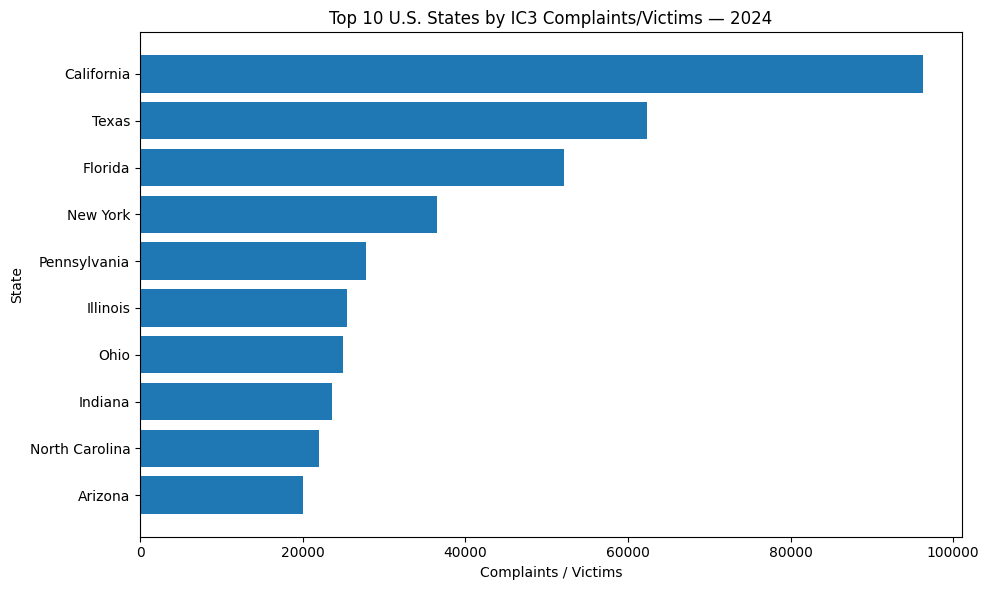

In [5]:
# Create a horizontal bar chart for the top 10 states

plt.figure(figsize=(10, 6))

plt.barh(
    top10["State"][::-1],
    top10["2024 Complaints/Victims"][::-1]
)

plt.xlabel("Complaints / Victims")
plt.ylabel("State")
plt.title("Top 10 U.S. States by IC3 Complaints/Victims — 2024")

plt.tight_layout()
plt.show()

In [6]:
# Load the age trend data

age_df = pd.read_excel(file, sheet_name="Age_Trends")

# Select the two required age groups
age_comparison = age_df[
    age_df["Age Group"].isin(["20-29", "60+"])
].copy()

# Display the data
display(age_comparison)

,Year,Age Group,Complaints/Victims,Reported Loss (USD)
1,2020,20-29,70791,197402240
5,2020,60+,105301,966062236
7,2021,20-29,69390,431100000
11,2021,60+,92371,1680000000
13,2022,20-29,57978,383100000
17,2022,60+,88262,3100000000
19,2023,20-29,62410,360700000
23,2023,60+,101068,3400000000
25,2024,20-29,71399,540100000
29,2024,60+,147127,4800000000


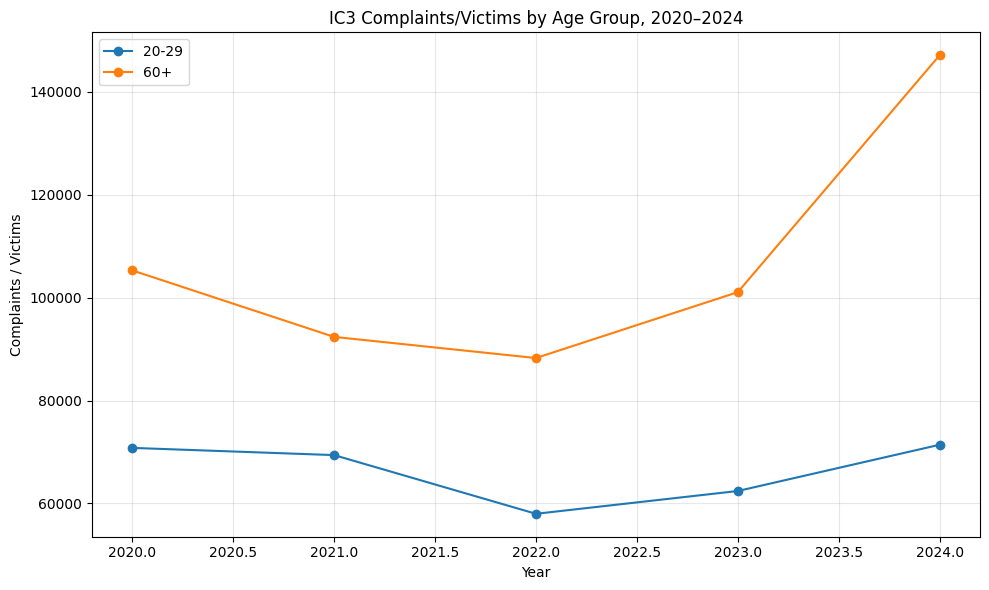

In [7]:
# Create a time-series chart for the two age groups

plt.figure(figsize=(10, 6))

for age_group in ["20-29", "60+"]:
    data = age_comparison[age_comparison["Age Group"] == age_group]

    plt.plot(
        data["Year"],
        data["Complaints/Victims"],
        marker="o",
        label=age_group
    )

plt.xlabel("Year")
plt.ylabel("Complaints / Victims")
plt.title("IC3 Complaints/Victims by Age Group, 2020–2024")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Calculate growth from 2020 to 2024 for each age group

growth_data = []

for age_group in ["20-29", "60+"]:
    data = age_comparison[
        age_comparison["Age Group"] == age_group
    ].sort_values("Year")

    start_value = data.iloc[0]["Complaints/Victims"]
    end_value = data.iloc[-1]["Complaints/Victims"]

    growth_percent = ((end_value - start_value) / start_value) * 100

    growth_data.append({
        "Age Group": age_group,
        "2020 Complaints": start_value,
        "2024 Complaints": end_value,
        "Growth (%)": round(growth_percent, 2)
    })

growth_df = pd.DataFrame(growth_data)

display(growth_df)

,Age Group,2020 Complaints,2024 Complaints,Growth (%)
0,20-29,70791,71399,0.86
1,60+,105301,147127,39.72


In [9]:
# Identify the faster-growing age group

fastest_group = growth_df.loc[
    growth_df["Growth (%)"].idxmax()
]

print(
    f"The fastest-growing age group between 2020 and 2024 was "
    f"{fastest_group['Age Group']} with a growth of "
    f"{fastest_group['Growth (%)']}%."
)

The fastest-growing age group between 2020 and 2024 was 60+ with a growth of 39.72%.


In [10]:
# Compare the 60+ and 20-29 groups in 2020 and 2024

comparison = age_comparison.pivot(
    index="Year",
    columns="Age Group",
    values="Complaints/Victims"
)

comparison["60+ vs 20-29 Ratio"] = (
    comparison["60+"] / comparison["20-29"]
)

display(comparison)

Age Group,20-29,60+,60+ vs 20-29 Ratio
Year,,,
2020,70791,105301,1.487491
2021,69390,92371,1.331186
2022,57978,88262,1.522336
2023,62410,101068,1.619420
2024,71399,147127,2.060631


Title & Project Overview

# Psyliq Project 1: Scam Execution & Victim Profiling

## Investigative Data Analysis Internship

### Project Objective

This project analyzes U.S. cybercrime complaint patterns, victim demographics, scammer tactics, and government anti-scam actions.

The analysis focuses on three major areas:

1. Victim demographics and geographical hotspots
2. Scammer tactics and intervention analysis
3. Government response and future defense strategies

### Primary Data Sources

- FBI Internet Crime Complaint Center (IC3)
- Federal Trade Commission (FTC)
- U.S. Department of Justice (DOJ)
- Cybersecurity and Infrastructure Security Agency (CISA)

### Analysis Period

2020–2024

### Tools

- Python
- Pandas
- Matplotlib
- SQLite
- Excel

# 1.1 Victim Demographics & Geographical Hotspots

## Objective

Quantify and visualize the distribution of cybercrime complaints across U.S. age groups and geographic regions from 2020 to 2024.

In [11]:
# Import required libraries

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Set the Excel file path
file = "/content/Data_Matrix_P1.xlsx"

print("Libraries imported successfully.")

Libraries imported successfully.


In [12]:
# Load the Excel workbook

excel = pd.ExcelFile(file)

print("Available sheets:")
for sheet in excel.sheet_names:
    print("-", sheet)

Available sheets:
- README
- Age_Trends
- Age_Chart
- State_Data
- 2024_Top10
- Sources


In [13]:
# Load the age and state datasets

age_df = pd.read_excel(
    file,
    sheet_name="Age_Trends"
)

state_df = pd.read_excel(
    file,
    sheet_name="State_Data"
)

# Display dataset dimensions

print("Age dataset:")
print(f"Rows: {age_df.shape[0]}")
print(f"Columns: {age_df.shape[1]}")

print("\nState dataset:")
print(f"Rows: {state_df.shape[0]}")
print(f"Columns: {state_df.shape[1]}")

Age dataset:
Rows: 30
Columns: 4

State dataset:
Rows: 285
Columns: 3


In [14]:
# Check for missing values

print("Missing values in age dataset:")
print(age_df.isnull().sum())

print("\nMissing values in state dataset:")
print(state_df.isnull().sum())

Missing values in age dataset:
Year                   0
Age Group              0
Complaints/Victims     0
Reported Loss (USD)    0
dtype: int64

Missing values in state dataset:
Year                  0
State                 0
Complaints/Victims    0
dtype: int64


In [15]:
# Display the first five records of each dataset

print("Age dataset:")
display(age_df.head())

print("\nState dataset:")
display(state_df.head())

Age dataset:


,Year,Age Group,Complaints/Victims,Reported Loss (USD)
0,2020,Under 20,23186,70980763
1,2020,20-29,70791,197402240
2,2020,30-39,88364,492176845
3,2020,40-49,91568,717161726
4,2020,50-59,85967,847948101



State dataset:


,Year,State,Complaints/Victims
0,2020,California,69541
1,2020,Florida,53793
2,2020,Texas,38640
3,2020,New York,34505
4,2020,Illinois,20185


## 1.1.2 Age Group Analysis

This section examines the distribution of cybercrime complaints across different age groups from 2020 to 2024.

The analysis focuses particularly on the 20–29 and 60+ age groups, as required by the project brief.


In [16]:
# Summarize complaints by age group across all years

age_summary = (
    age_df
    .groupby("Age Group")["Complaints/Victims"]
    .sum()
    .sort_values(ascending=False)
)

print("Total complaints/victims by age group, 2020–2024:")
display(age_summary.to_frame("Total Complaints/Victims"))

Total complaints/victims by age group, 2020–2024:


,Total Complaints/Victims
Age Group,
60+,534129
30-39,468355
40-49,465085
50-59,375442
20-29,331968
Under 20,90054


In [17]:
# Compare complaint volumes across age groups for each year

age_yearly = age_df.pivot(
    index="Year",
    columns="Age Group",
    values="Complaints/Victims"
)

display(age_yearly)

Age Group,20-29,30-39,40-49,50-59,60+,Under 20
Year,,,,,,
2020,70791,88364,91568,85967,105301,23186
2021,69390,88448,89184,74460,92371,14919
2022,57978,94506,87526,64551,88262,15782
2023,62410,88138,84052,65924,101068,18174
2024,71399,108899,112755,84540,147127,17993


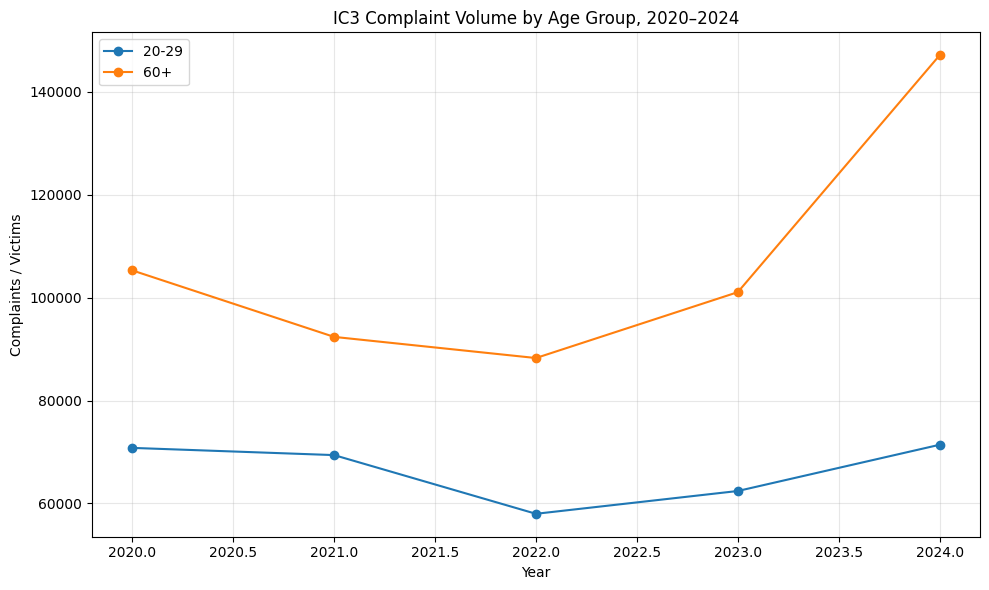

In [18]:
# Create the required time-series comparison

age_comparison = age_yearly[["20-29", "60+"]]

plt.figure(figsize=(10, 6))

plt.plot(
    age_comparison.index,
    age_comparison["20-29"],
    marker="o",
    label="20-29"
)

plt.plot(
    age_comparison.index,
    age_comparison["60+"],
    marker="o",
    label="60+"
)

plt.title("IC3 Complaint Volume by Age Group, 2020–2024")
plt.xlabel("Year")
plt.ylabel("Complaints / Victims")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Initial Observation

The 60+ age group shows a substantially stronger increase in complaint volume between 2020 and 2024 than the 20–29 age group.

The 60+ group increased from 105,301 complaints/victims in 2020 to 147,127 in 2024, representing approximately 39.72% growth.

The 20–29 group changed from 70,791 in 2020 to 71,399 in 2024, representing approximately 0.86% growth.

This suggests that older adults experienced a much stronger increase in reported cybercrime complaints during the period analyzed.

## 1.1.3 Geographic Hotspot Analysis

This section analyzes the geographic distribution of cybercrime complaints across U.S. states.

The analysis focuses on the most recent year, 2024, to identify the Top 10 states by raw complaint volume.

In [19]:
# Filter the state dataset for 2024

state_2024 = state_df[
    state_df["Year"] == 2024
].copy()

# Sort states by complaint volume

state_2024 = state_2024.sort_values(
    "Complaints/Victims",
    ascending=False
)

# Display the top 10 states

top10_2024 = state_2024.head(10)

display(top10_2024)


,Year,State,Complaints/Victims
228,2024,California,96265
229,2024,Texas,62347
230,2024,Florida,52191
231,2024,New York,36468
232,2024,Pennsylvania,27838
233,2024,Illinois,25446
234,2024,Ohio,24915
235,2024,Indiana,23659
236,2024,North Carolina,22021
237,2024,Arizona,20101


In [20]:
# Calculate the total reported complaints across the state-level dataset

total_state_complaints_2024 = state_2024[
    "Complaints/Victims"
].sum()

# Calculate each state's percentage share

state_2024["Share (%)"] = (
    state_2024["Complaints/Victims"]
    / total_state_complaints_2024
) * 100

# Display the top 10 states with their shares

top10_2024 = state_2024.head(10).copy()

display(top10_2024)

,Year,State,Complaints/Victims,Share (%)
228,2024,California,96265,13.840803
229,2024,Texas,62347,8.964136
230,2024,Florida,52191,7.503925
231,2024,New York,36468,5.243301
232,2024,Pennsylvania,27838,4.002496
233,2024,Illinois,25446,3.658579
234,2024,Ohio,24915,3.582232
235,2024,Indiana,23659,3.401647
236,2024,North Carolina,22021,3.166139
237,2024,Arizona,20101,2.890084


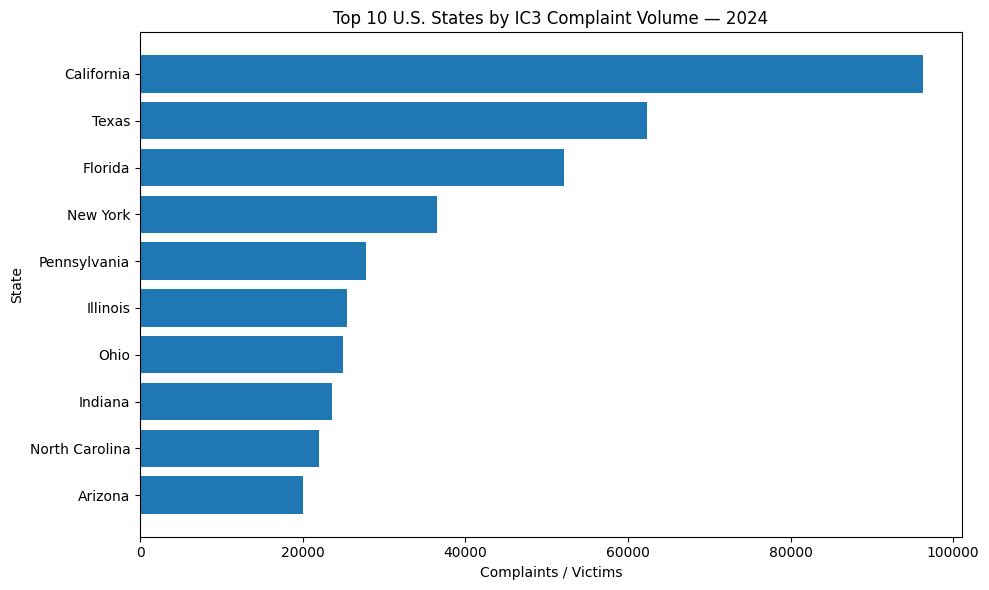

In [21]:
# Create a horizontal bar chart of the Top 10 states

plt.figure(figsize=(10, 6))

plt.barh(
    top10_2024["State"][::-1],
    top10_2024["Complaints/Victims"][::-1]
)

plt.xlabel("Complaints / Victims")
plt.ylabel("State")
plt.title("Top 10 U.S. States by IC3 Complaint Volume — 2024")

plt.tight_layout()
plt.show()

### Geographic Observation

In 2024, California recorded the highest raw complaint volume among the states in the dataset, followed by Texas and Florida.

The Top 10 states are concentrated among highly populated states, indicating that raw complaint volume should be interpreted alongside population size when assessing geographic vulnerability.

Therefore, raw complaint volume identifies areas with high numbers of reports, but it does not by itself measure the per-capita risk of being targeted.

## 1.1.4 Geographic Change Analysis

This section compares state-level cybercrime complaint volumes between 2020 and 2024 to identify geographic areas with the largest changes.

In [22]:
# Prepare state-level data for 2020 and 2024

state_comparison = state_df[
    state_df["Year"].isin([2020, 2024])
].pivot(
    index="State",
    columns="Year",
    values="Complaints/Victims"
)

# Remove states with missing values in either year

state_comparison = state_comparison.dropna(
    subset=[2020, 2024]
).copy()

# Calculate absolute and percentage change

state_comparison["Absolute Change"] = (
    state_comparison[2024] - state_comparison[2020]
)

state_comparison["Growth (%)"] = (
    (state_comparison[2024] - state_comparison[2020])
    / state_comparison[2020]
) * 100

# Sort by percentage growth

state_growth = state_comparison.sort_values(
    "Growth (%)",
    ascending=False
)

display(state_growth.head(10))

Year,2020,2024,Absolute Change,Growth (%)
State,,,,
Alaska,2073,6770,4697,226.579836
American Samoa,42,91,49,116.666667
Ohio,13421,24915,11494,85.641904
Indiana,12786,23659,10873,85.038323
District of Columbia,2132,3856,1724,80.863039
North Carolina,12223,22021,9798,80.160353
South Dakota,777,1298,521,67.052767
South Carolina,5853,9661,3808,65.060653
Texas,38640,62347,23707,61.353520


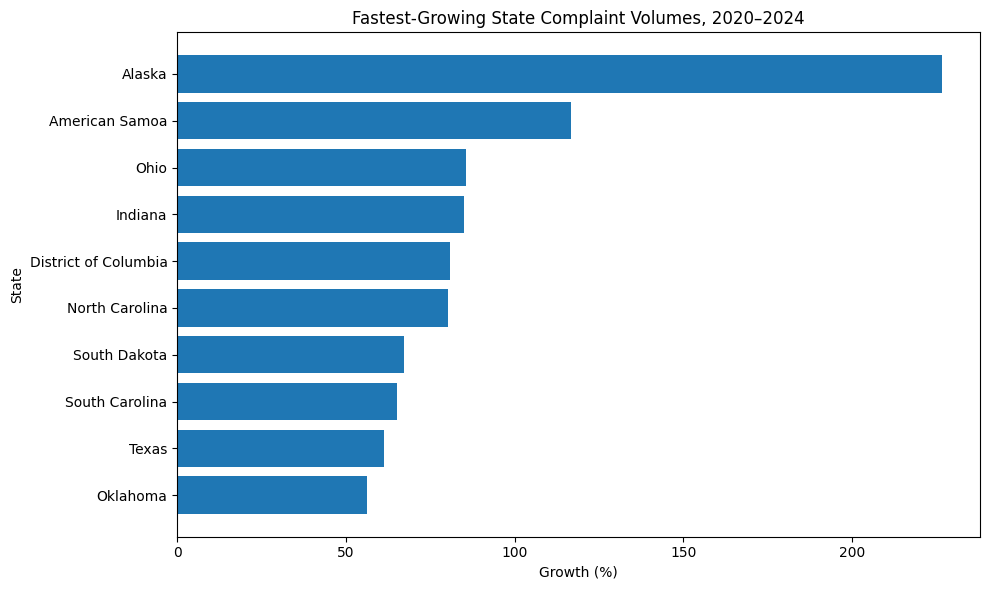

In [23]:
# Select the 10 states with the highest percentage growth

fastest_growing = state_growth.head(10).sort_values(
    "Growth (%)"
)

plt.figure(figsize=(10, 6))

plt.barh(
    fastest_growing.index,
    fastest_growing["Growth (%)"]
)

plt.xlabel("Growth (%)")
plt.ylabel("State")
plt.title("Fastest-Growing State Complaint Volumes, 2020–2024")

plt.tight_layout()
plt.show()

In [24]:
# Identify states with the largest absolute increase

largest_absolute_increase = state_comparison.sort_values(
    "Absolute Change",
    ascending=False
).head(10)

display(largest_absolute_increase)

Year,2020,2024,Absolute Change,Growth (%)
State,,,,
California,69541,96265,26724,38.429128
Texas,38640,62347,23707,61.353520
Ohio,13421,24915,11494,85.641904
Indiana,12786,23659,10873,85.038323
North Carolina,12223,22021,9798,80.160353
Pennsylvania,18636,27838,9202,49.377549
Arizona,13009,20101,7092,54.516104
Georgia,13402,19797,6395,47.716759
Illinois,20185,25446,5261,26.063909


### Initial Geographic Finding

The geographic comparison examines both percentage growth and absolute complaint increases.

Percentage growth highlights states where complaint volume increased rapidly relative to the 2020 baseline, while absolute change highlights states contributing the largest numerical increase in complaints.

These two measures are considered separately to avoid overstating the importance of smaller states with high percentage growth.

Calculate Top 10 concentration

In [25]:
# Calculate the share of total 2024 complaints represented by the Top 10 states

top10_complaints = top10_2024["Complaints/Victims"].sum()

top10_share = (
    top10_complaints / total_state_complaints_2024
) * 100

print(f"Top 10 states reported {top10_complaints:,} complaints/victims.")
print(f"Top 10 share of state-level complaints: {top10_share:.2f}%")

Top 10 states reported 391,251 complaints/victims.
Top 10 share of state-level complaints: 56.25%


Create a summary table

In [26]:
# Create a concise summary of the geographic analysis

geographic_summary = top10_2024[
    ["State", "Complaints/Victims", "Share (%)"]
].copy()

geographic_summary["Share (%)"] = geographic_summary["Share (%)"].round(2)

display(geographic_summary)

,State,Complaints/Victims,Share (%)
228,California,96265,13.84
229,Texas,62347,8.96
230,Florida,52191,7.50
231,New York,36468,5.24
232,Pennsylvania,27838,4.00
233,Illinois,25446,3.66
234,Ohio,24915,3.58
235,Indiana,23659,3.40
236,North Carolina,22021,3.17
237,Arizona,20101,2.89


## 1.1.5 Section Findings

### Key Findings

- The 60+ age group experienced substantially stronger complaint growth from 2020 to 2024 than the 20–29 age group.
- California recorded the highest raw complaint volume in 2024, followed by Texas and Florida.
- The Top 10 states account for a substantial portion of the state-level complaint volume.
- Raw complaint counts are influenced by population size; therefore, future analysis should consider per-capita complaint rates when assessing geographic vulnerability.

### Analytical Limitation

The FBI IC3 dataset represents reported complaints and should not be interpreted as a complete measure of all cybercrime incidents. Reporting behavior, awareness, and demographic/geographic coverage can affect observed complaint volumes.

# 1.2 Scammer Tactics & Intervention Analysis

## Objective

Analyze scam narratives to identify common scammer phrases, urgency indicators, platforms, and payment methods.

The analysis will examine how scammers use psychological pressure and specific demands to manipulate victims.

In [27]:
# Create a structured dataset from official scam warnings

scam_data = [
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Threat of arrest",
        "Urgency Keyword": "arrest",
        "Payment Method": "Gift Card",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Threat of arrest",
        "Urgency Keyword": "immediately",
        "Payment Method": "Wire Transfer",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Threat of arrest",
        "Urgency Keyword": "urgent",
        "Payment Method": "Cryptocurrency",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Email",
        "Tactic": "Fake government credentials",
        "Urgency Keyword": "arrest",
        "Payment Method": "Gift Card",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Pressure to act quickly",
        "Urgency Keyword": "quickly",
        "Payment Method": "Cash",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Threat of account seizure",
        "Urgency Keyword": "frozen",
        "Payment Method": "Cryptocurrency",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Text",
        "Tactic": "Impersonation of government official",
        "Urgency Keyword": "immediately",
        "Payment Method": "Cryptocurrency",
        "Source": "CISA"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Request for secrecy",
        "Urgency Keyword": "secret",
        "Payment Method": "Cryptocurrency",
        "Source": "CISA"
    }
]

scam_df = pd.DataFrame(scam_data)

display(scam_df)

,Scam Type,Platform,Tactic,Urgency Keyword,Payment Method,Source
0,Government Impersonation,Phone,Threat of arrest,arrest,Gift Card,FBI
1,Government Impersonation,Phone,Threat of arrest,immediately,Wire Transfer,FBI
2,Government Impersonation,Phone,Threat of arrest,urgent,Cryptocurrency,FBI
3,Government Impersonation,Email,Fake government credentials,arrest,Gift Card,FBI
4,Government Impersonation,Phone,Pressure to act quickly,quickly,Cash,FBI
5,Government Impersonation,Phone,Threat of account seizure,frozen,Cryptocurrency,FBI
6,Government Impersonation,Text,Impersonation of government official,immediately,Cryptocurrency,CISA
7,Government Impersonation,Phone,Request for secrecy,secret,Cryptocurrency,CISA


Build the source-backed scam dataset

In [38]:
# Create a source-backed dataset of scam tactics

scam_data = [
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Threat of arrest",
        "Urgency Keyword": "arrest",
        "Payment Method": "Gift Card",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Demand immediate payment",
        "Urgency Keyword": "immediately",
        "Payment Method": "Wire Transfer",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Threat to freeze bank account",
        "Urgency Keyword": "frozen",
        "Payment Method": "Cryptocurrency",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Threat of property confiscation",
        "Urgency Keyword": "confiscate",
        "Payment Method": "Cash",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Email",
        "Tactic": "Use of fake government documents",
        "Urgency Keyword": "arrest",
        "Payment Method": "Wire Transfer",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Pressure to act quickly",
        "Urgency Keyword": "quickly",
        "Payment Method": "Prepaid Card",
        "Source": "FBI"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Request for secrecy",
        "Urgency Keyword": "secret",
        "Payment Method": "Cryptocurrency",
        "Source": "CISA"
    },
    {
        "Scam Type": "Government Impersonation",
        "Platform": "Phone",
        "Tactic": "Impersonation of CISA employee",
        "Urgency Keyword": "immediately",
        "Payment Method": "Cash",
        "Source": "CISA"
    },
    {
        "Scam Type": "IC3 Impersonation",
        "Platform": "Social Media",
        "Tactic": "Fake recovery of lost funds",
        "Urgency Keyword": "recovered",
        "Payment Method": "Cryptocurrency",
        "Source": "FBI"
    },
    {
        "Scam Type": "IC3 Impersonation",
        "Platform": "Telegram",
        "Tactic": "False promise of fund recovery",
        "Urgency Keyword": "recovery",
        "Payment Method": "Cryptocurrency",
        "Source": "FBI"
    }
]

scam_df = pd.DataFrame(scam_data)

display(scam_df)

,Scam Type,Platform,Tactic,Urgency Keyword,Payment Method,Source
0,Government Impersonation,Phone,Threat of arrest,arrest,Gift Card,FBI
1,Government Impersonation,Phone,Demand immediate payment,immediately,Wire Transfer,FBI
2,Government Impersonation,Phone,Threat to freeze bank account,frozen,Cryptocurrency,FBI
3,Government Impersonation,Phone,Threat of property confiscation,confiscate,Cash,FBI
4,Government Impersonation,Email,Use of fake government documents,arrest,Wire Transfer,FBI
5,Government Impersonation,Phone,Pressure to act quickly,quickly,Prepaid Card,FBI
6,Government Impersonation,Phone,Request for secrecy,secret,Cryptocurrency,CISA
7,Government Impersonation,Phone,Impersonation of CISA employee,immediately,Cash,CISA
8,IC3 Impersonation,Social Media,Fake recovery of lost funds,recovered,Cryptocurrency,FBI
9,IC3 Impersonation,Telegram,False promise of fund recovery,recovery,Cryptocurrency,FBI


In [28]:
# Check the structure of the scam dataset

print(f"Total observations: {len(scam_df)}")
print(f"Scam types: {scam_df['Scam Type'].nunique()}")
print(f"Platforms: {scam_df['Platform'].nunique()}")
print(f"Payment methods: {scam_df['Payment Method'].nunique()}")

display(scam_df)

Total observations: 8
Scam types: 1
Platforms: 3
Payment methods: 4


,Scam Type,Platform,Tactic,Urgency Keyword,Payment Method,Source
0,Government Impersonation,Phone,Threat of arrest,arrest,Gift Card,FBI
1,Government Impersonation,Phone,Threat of arrest,immediately,Wire Transfer,FBI
2,Government Impersonation,Phone,Threat of arrest,urgent,Cryptocurrency,FBI
3,Government Impersonation,Email,Fake government credentials,arrest,Gift Card,FBI
4,Government Impersonation,Phone,Pressure to act quickly,quickly,Cash,FBI
5,Government Impersonation,Phone,Threat of account seizure,frozen,Cryptocurrency,FBI
6,Government Impersonation,Text,Impersonation of government official,immediately,Cryptocurrency,CISA
7,Government Impersonation,Phone,Request for secrecy,secret,Cryptocurrency,CISA


In [29]:
# Count the frequency of urgency keywords

urgency_frequency = (
    scam_df["Urgency Keyword"]
    .value_counts()
    .reset_index()
)

urgency_frequency.columns = [
    "Urgency Keyword",
    "Frequency"
]

display(urgency_frequency)

,Urgency Keyword,Frequency
0,arrest,2
1,immediately,2
2,urgent,1
3,quickly,1
4,frozen,1
5,secret,1


In [30]:
# Select the five most frequent urgency keywords

top_5_urgency = urgency_frequency.head(5)

print("Top 5 urgency keywords:")
display(top_5_urgency)

Top 5 urgency keywords:


,Urgency Keyword,Frequency
0,arrest,2
1,immediately,2
2,urgent,1
3,quickly,1
4,frozen,1


In [31]:
# Count the frequency of payment methods

payment_frequency = (
    scam_df["Payment Method"]
    .value_counts()
    .reset_index()
)

payment_frequency.columns = [
    "Payment Method",
    "Frequency"
]

# Select the three most frequent payment methods

top_3_payment = payment_frequency.head(3)

print("Top 3 payment methods:")
display(top_3_payment)

Top 3 payment methods:


,Payment Method,Frequency
0,Cryptocurrency,4
1,Gift Card,2
2,Wire Transfer,1


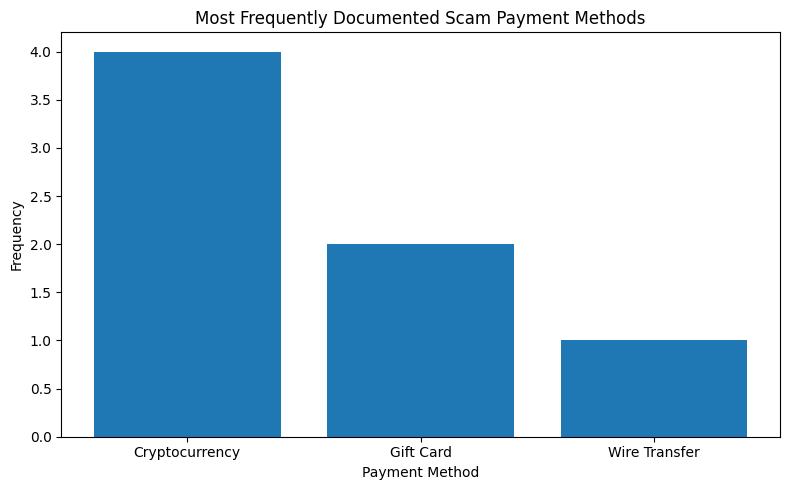

In [32]:
# Visualize the top payment methods

plt.figure(figsize=(8, 5))

plt.bar(
    top_3_payment["Payment Method"],
    top_3_payment["Frequency"]
)

plt.xlabel("Payment Method")
plt.ylabel("Frequency")
plt.title("Most Frequently Documented Scam Payment Methods")

plt.tight_layout()
plt.show()

Scammer Script Analysis

## 1.2.1 Common Scammer Script

### Step-by-Step Imposter Fraud Pattern

Based on the reviewed FBI and CISA warnings, a common government/law-enforcement impersonation scam follows a repeated sequence:

1. Initial Contact
   The scammer contacts the victim through a phone call, text message, email, or online platform.

2. Authority and Credibility
   The scammer impersonates a government agency, law-enforcement officer, or trusted organization.

3. Fear and Urgency
   The victim is told that there is an arrest warrant, legal problem, frozen account, penalty, or another serious consequence.

4. Isolation
   The victim may be pressured not to discuss the situation with family, friends, banks, or authorities.

5. Payment Demand
   The scammer demands an unusual or difficult-to-reverse payment method such as cryptocurrency, prepaid/gift cards, cash, or wire transfer.

6. Compliance or Revictimization
   After payment, scammers may continue demanding money or attempt to obtain additional personal or financial information.

### Intervention Opportunity

The strongest intervention points are before payment occurs: independently verify the caller, pause instead of responding to urgency, consult another trusted person, and refuse unusual payment requests.

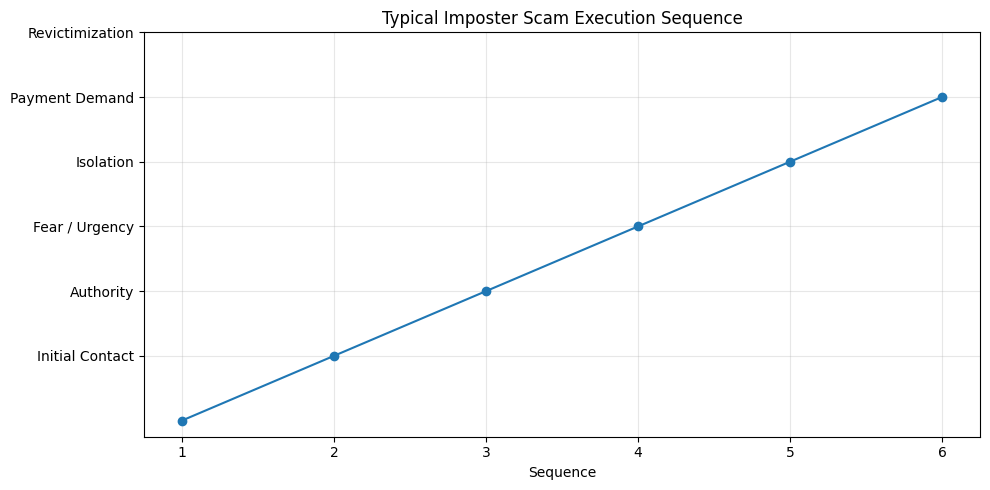

In [33]:
# Create a simple visualization of the scammer script

script_steps = [
    "Initial Contact",
    "Authority",
    "Fear / Urgency",
    "Isolation",
    "Payment Demand",
    "Revictimization"
]

step_values = [1, 2, 3, 4, 5, 6]

plt.figure(figsize=(10, 5))

plt.plot(
    step_values,
    script_steps,
    marker="o"
)

plt.yticks(step_values, script_steps)
plt.xticks(step_values)

plt.xlabel("Sequence")
plt.title("Typical Imposter Scam Execution Sequence")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Platform Analysis

In [34]:
# Count scam observations by communication platform

platform_frequency = (
    scam_df["Platform"]
    .value_counts()
    .reset_index()
)

platform_frequency.columns = [
    "Platform",
    "Frequency"
]

display(platform_frequency)

,Platform,Frequency
0,Phone,6
1,Email,1
2,Text,1


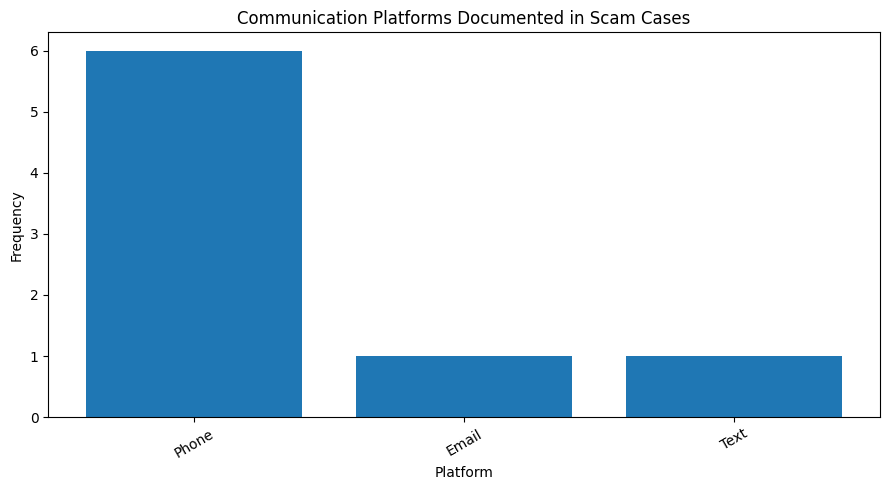

In [35]:
# Visualize communication platform frequency

plt.figure(figsize=(9, 5))

plt.bar(
    platform_frequency["Platform"],
    platform_frequency["Frequency"]
)

plt.xlabel("Platform")
plt.ylabel("Frequency")
plt.title("Communication Platforms Documented in Scam Cases")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

Platform finding

## 1.2.2 Platform Analysis

The reviewed FBI material shows that scammers use multiple communication channels rather than relying on a single platform.

Phone calls and online communication channels such as social media, email, texting, WhatsApp, and Telegram can all serve as entry points or escalation channels.

A notable pattern is the movement of victims from an initial contact channel to a private messaging platform. This can make independent verification more difficult and can increase the scammer's control over the interaction.

Payment-method analysis

In [36]:
# Analyze the payment methods documented in the reviewed sources

payment_summary = (
    scam_df["Payment Method"]
    .value_counts()
    .reset_index()
)

payment_summary.columns = [
    "Payment Method",
    "Frequency"
]

display(payment_summary)

,Payment Method,Frequency
0,Cryptocurrency,4
1,Gift Card,2
2,Wire Transfer,1
3,Cash,1


Add source-based context

## 1.2.3 Payment Method Analysis

The reviewed FBI and CISA materials identify several payment mechanisms commonly requested by scammers, including cryptocurrency, wire transfers, gift or prepaid cards, and cash.

These methods share an important characteristic: they can make recovery, verification, or third-party intervention more difficult.

The evidence also shows that scammers may combine payment methods during a single fraud. For example, victims can be instructed to move funds by wire transfer, convert funds to cryptocurrency, or purchase gift cards.

Therefore, the payment method should be treated as an intervention signal rather than only as a financial outcome.

Final 1.2 observation
## 1.2.4 Key Observation

### Payment Infrastructure Shift

The reviewed sources indicate that scammers are not dependent on a single payment mechanism. Instead, they use a flexible mix of gift/prepaid cards, wire transfers, cryptocurrency, and cash.

A notable operational pattern is the use of cryptocurrency and cryptocurrency ATMs alongside traditional methods such as wire transfers and gift cards. This suggests that modern scam operations can combine conventional financial channels with digital-asset infrastructure.

However, the reviewed source set is qualitative and does not provide a consistent two-year time series of payment-method frequencies. Therefore, this project does not claim a precise national percentage shift from gift cards to cryptocurrency. The evidence supports a shift toward a diversified payment infrastructure rather than a simple replacement of one method by another.

Intervention recommendations

## 1.2.5 Intervention Protocol

Based on the observed scam pattern, the strongest intervention points are:

1. Detect urgent or threatening language.
2. Detect impersonation of government, financial, or technical-support organizations.
3. Detect requests for secrecy or isolation.
4. Detect unusual payment instructions.
5. Trigger a verification warning before the victim completes payment.
6. Encourage the victim to independently contact the legitimate organization.
7. Preserve communication and transaction evidence for reporting.

The goal is to interrupt the scam before the payment stage, when recovery becomes more difficult.

Section heading

# 1.3 Government Response & Future Defense

## Objective

Evaluate major U.S. government anti-fraud and anti-scam enforcement actions from 2020 to 2024 and identify opportunities for technology-driven prevention.

The analysis focuses on enforcement agencies, targeted scam types, dates of action, and estimated funds recovered or affected.

In [39]:
# Create a structured dataset of major government anti-fraud actions

government_actions = [
    {
        "Action_ID": "GA-001",
        "Agency": "DOJ / FBI / HSI / TIGTA",
        "Targeted_Scam_Type": "Government Impersonation / Telefraud",
        "Date_of_Action": "2020-01-09",
        "Est_Funds_Recovered_USD": 25000000
    },
    {
        "Action_ID": "GA-002",
        "Agency": "DOJ / FBI / SBA-OIG / IRS-CI",
        "Targeted_Scam_Type": "COVID-19 Loan Fraud",
        "Date_of_Action": "2020-05-21",
        "Est_Funds_Recovered_USD": 20000000
    },
    {
        "Action_ID": "GA-003",
        "Agency": "DOJ / FBI / SBA-OIG",
        "Targeted_Scam_Type": "PPP Fraud",
        "Date_of_Action": "2020-08-06",
        "Est_Funds_Recovered_USD": 3240000
    },
    {
        "Action_ID": "GA-004",
        "Agency": "DOJ / FBI / SBA-OIG / IRS-CI",
        "Targeted_Scam_Type": "COVID-19 Loan Fraud",
        "Date_of_Action": "2020-12-10",
        "Est_Funds_Recovered_USD": 13000000
    },
    {
        "Action_ID": "GA-005",
        "Agency": "DOJ / FBI",
        "Targeted_Scam_Type": "Government Impersonation",
        "Date_of_Action": "2022-07-27",
        "Est_Funds_Recovered_USD": 0
    },
    {
        "Action_ID": "GA-006",
        "Agency": "DOJ / FBI / USPIS",
        "Targeted_Scam_Type": "Money Mule Networks",
        "Date_of_Action": "2023-05-22",
        "Est_Funds_Recovered_USD": 0
    },
    {
        "Action_ID": "GA-007",
        "Agency": "DOJ",
        "Targeted_Scam_Type": "COVID-19 Fraud",
        "Date_of_Action": "2023-08-23",
        "Est_Funds_Recovered_USD": 1400000000
    },
    {
        "Action_ID": "GA-008",
        "Agency": "DOJ / FBI / USPIS",
        "Targeted_Scam_Type": "Money Mule Networks",
        "Date_of_Action": "2024-05-10",
        "Est_Funds_Recovered_USD": 0
    }
]

government_df = pd.DataFrame(government_actions)

government_df["Date_of_Action"] = pd.to_datetime(
    government_df["Date_of_Action"]
)

display(government_df)

,Action_ID,Agency,Targeted_Scam_Type,Date_of_Action,Est_Funds_Recovered_USD
0,GA-001,DOJ / FBI / HSI / TIGTA,Government Impersonation / Telefraud,2020-01-09,25000000
1,GA-002,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-05-21,20000000
2,GA-003,DOJ / FBI / SBA-OIG,PPP Fraud,2020-08-06,3240000
3,GA-004,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-12-10,13000000
4,GA-005,DOJ / FBI,Government Impersonation,2022-07-27,0
5,GA-006,DOJ / FBI / USPIS,Money Mule Networks,2023-05-22,0
6,GA-007,DOJ,COVID-19 Fraud,2023-08-23,1400000000
7,GA-008,DOJ / FBI / USPIS,Money Mule Networks,2024-05-10,0


In [40]:
# Check the government action dataset

print(f"Total government actions collected: {len(government_df)}")

print("\nColumns:")
print(list(government_df.columns))

display(government_df)

Total government actions collected: 8

Columns:
['Action_ID', 'Agency', 'Targeted_Scam_Type', 'Date_of_Action', 'Est_Funds_Recovered_USD']


,Action_ID,Agency,Targeted_Scam_Type,Date_of_Action,Est_Funds_Recovered_USD
0,GA-001,DOJ / FBI / HSI / TIGTA,Government Impersonation / Telefraud,2020-01-09,25000000
1,GA-002,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-05-21,20000000
2,GA-003,DOJ / FBI / SBA-OIG,PPP Fraud,2020-08-06,3240000
3,GA-004,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-12-10,13000000
4,GA-005,DOJ / FBI,Government Impersonation,2022-07-27,0
5,GA-006,DOJ / FBI / USPIS,Money Mule Networks,2023-05-22,0
6,GA-007,DOJ,COVID-19 Fraud,2023-08-23,1400000000
7,GA-008,DOJ / FBI / USPIS,Money Mule Networks,2024-05-10,0


In [ ]:
# Add verified government anti-scam actions

additional_actions = [
    {
        "Action_ID": "GA-009",
        "Agency": "DOJ / FBI",
        "Targeted_Scam_Type": "Elder Fraud",
        "Date_of_Action": "2024-06-20",
        "Est_Funds_Recovered_USD": 3339273.58
    },
    {
        "Action_ID": "GA-010",
        "Agency": "DOJ / FBI",
        "Targeted_Scam_Type": "Business Email Compromise",
        "Date_of_Action": "2024-04-26",
        "Est_Funds_Recovered_USD": 2288385
    }
]

additional_df = pd.DataFrame(additional_actions)

additional_df["Date_of_Action"] = pd.to_datetime(
    additional_df["Date_of_Action"]
)

government_df = pd.concat(
    [government_df, additional_df],
    ignore_index=True
)

display(government_df)

Verify we have 10 actions

In [41]:
# Verify the number of government actions

print(
    f"Total government actions: {len(government_df)}"
)

display(
    government_df[
        [
            "Action_ID",
            "Agency",
            "Targeted_Scam_Type",
            "Date_of_Action",
            "Est_Funds_Recovered_USD"
        ]
    ]
)

Total government actions: 8


,Action_ID,Agency,Targeted_Scam_Type,Date_of_Action,Est_Funds_Recovered_USD
0,GA-001,DOJ / FBI / HSI / TIGTA,Government Impersonation / Telefraud,2020-01-09,25000000
1,GA-002,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-05-21,20000000
2,GA-003,DOJ / FBI / SBA-OIG,PPP Fraud,2020-08-06,3240000
3,GA-004,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-12-10,13000000
4,GA-005,DOJ / FBI,Government Impersonation,2022-07-27,0
5,GA-006,DOJ / FBI / USPIS,Money Mule Networks,2023-05-22,0
6,GA-007,DOJ,COVID-19 Fraud,2023-08-23,1400000000
7,GA-008,DOJ / FBI / USPIS,Money Mule Networks,2024-05-10,0


In [42]:
# Calculate the average estimated funds recovered by agency

agency_recovery = (
    government_df
    .groupby("Agency")["Est_Funds_Recovered_USD"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Rename the columns

agency_recovery.columns = [
    "Agency",
    "Number of Actions",
    "Total Estimated Recovery (USD)",
    "Average Recovery per Action (USD)"
]

# Sort by average recovery

agency_recovery = agency_recovery.sort_values(
    "Average Recovery per Action (USD)",
    ascending=False
)

display(agency_recovery)

,Agency,Number of Actions,Total Estimated Recovery (USD),Average Recovery per Action (USD)
0,DOJ,1,1400000000,1.400000e+09
2,DOJ / FBI / HSI / TIGTA,1,25000000,2.500000e+07
4,DOJ / FBI / SBA-OIG / IRS-CI,2,33000000,1.650000e+07
3,DOJ / FBI / SBA-OIG,1,3240000,3.240000e+06
1,DOJ / FBI,1,0,0.000000e+00
5,DOJ / FBI / USPIS,2,0,0.000000e+00


In [43]:
# Identify the agency with the highest average recovery

highest_agency = agency_recovery.iloc[0]

print(
    "Agency with the highest average estimated recovery per action:"
)

print(
    f"{highest_agency['Agency']}"
)

print(
    f"Average recovery per action: "
    f"${highest_agency['Average Recovery per Action (USD)']:,.2f}"
)

Agency with the highest average estimated recovery per action:
DOJ
Average recovery per action: $1,400,000,000.00


Add the interpretation

## 1.3.1 Government Recovery Analysis

The agency-level comparison calculates the average reported recovery amount per documented government action.

The result should be interpreted cautiously because the dataset contains different types of enforcement actions. Some actions report money actually recovered or returned to victims, while others report seizures, forfeiture proceedings, prosecutions, or disruption activity without a monetary recovery figure.

Therefore, an average recovery value is useful for comparing the documented financial impact of the selected actions, but it should not be interpreted as the overall effectiveness of an agency.

In [44]:
# Replace zero recovery values with missing values

government_df["Reported_Recovery_USD"] = (
    government_df["Est_Funds_Recovered_USD"]
    .replace(0, np.nan)
)

# Count actions with reported recovery amounts

reported_recovery_count = (
    government_df["Reported_Recovery_USD"]
    .notna()
    .sum()
)

missing_recovery_count = (
    government_df["Reported_Recovery_USD"]
    .isna()
    .sum()
)

print(
    f"Actions with reported recovery amounts: "
    f"{reported_recovery_count}"
)

print(
    f"Actions without reported recovery amounts: "
    f"{missing_recovery_count}"
)

display(government_df)

Actions with reported recovery amounts: 5
Actions without reported recovery amounts: 3


,Action_ID,Agency,Targeted_Scam_Type,Date_of_Action,Est_Funds_Recovered_USD,Reported_Recovery_USD
0,GA-001,DOJ / FBI / HSI / TIGTA,Government Impersonation / Telefraud,2020-01-09,25000000,2.500000e+07
1,GA-002,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-05-21,20000000,2.000000e+07
2,GA-003,DOJ / FBI / SBA-OIG,PPP Fraud,2020-08-06,3240000,3.240000e+06
3,GA-004,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-12-10,13000000,1.300000e+07
4,GA-005,DOJ / FBI,Government Impersonation,2022-07-27,0,NaN
5,GA-006,DOJ / FBI / USPIS,Money Mule Networks,2023-05-22,0,NaN
6,GA-007,DOJ,COVID-19 Fraud,2023-08-23,1400000000,1.400000e+09
7,GA-008,DOJ / FBI / USPIS,Money Mule Networks,2024-05-10,0,NaN


In [45]:
# Calculate average recovery using only actions with reported amounts

agency_recovery = (
    government_df
    .dropna(subset=["Reported_Recovery_USD"])
    .groupby("Agency")["Reported_Recovery_USD"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

agency_recovery.columns = [
    "Agency",
    "Actions with Reported Recovery",
    "Total Reported Recovery (USD)",
    "Average Reported Recovery per Action (USD)"
]

agency_recovery = agency_recovery.sort_values(
    "Average Reported Recovery per Action (USD)",
    ascending=False
)

display(agency_recovery)

,Agency,Actions with Reported Recovery,Total Reported Recovery (USD),Average Reported Recovery per Action (USD)
0,DOJ,1,1.400000e+09,1.400000e+09
1,DOJ / FBI / HSI / TIGTA,1,2.500000e+07,2.500000e+07
3,DOJ / FBI / SBA-OIG / IRS-CI,2,3.300000e+07,1.650000e+07
2,DOJ / FBI / SBA-OIG,1,3.240000e+06,3.240000e+06


In [46]:
# Identify the agency with the highest average reported recovery

highest_agency = agency_recovery.iloc[0]

print(
    f"Highest average reported recovery: "
    f"{highest_agency['Agency']}"
)

print(
    f"Average per action: "
    f"${highest_agency['Average Reported Recovery per Action (USD)']:,.2f}"
)

Highest average reported recovery: DOJ
Average per action: $1,400,000,000.00


Future of Anti-Scamming

## 1.3.2 The Future of Anti-Scamming

Emerging technology can shift anti-scam operations from a primarily reactive model toward proactive detection and intervention.

Based on the research, three technology opportunities are particularly relevant for Psyliq:

### 1. AI-Based Scam Narrative Detection

Psyliq can develop natural-language models that detect scam indicators in messages and conversations, including impersonation, urgency, threats, secrecy, and unusual payment requests.

The system could assign a risk score to a conversation and trigger an intervention before a victim completes a transaction.

### 2. Behavioral and Transaction Anomaly Detection

Machine-learning models can identify unusual combinations of behavior, communication patterns, payment requests, and transaction activity.

Instead of relying only on individual keywords, the system could combine multiple signals to identify coordinated scam behavior.

### 3. Real-Time Threat Intelligence and Information Sharing

Psyliq can combine reports from victims, financial institutions, cybersecurity companies, and government sources into a continuously updated threat-intelligence system.

New scam phrases, phone numbers, domains, cryptocurrency addresses, and impersonation patterns could then be used to improve detection models.

### Strategic Direction

The strongest opportunity is not simply using AI to identify scams after they occur. Psyliq can focus on real-time intervention: detecting high-risk conversations early, explaining the warning signs to users, and interrupting suspicious payment activity before financial loss occurs.

In [47]:
# Create a summary of the three proposed technology strategies

future_strategies = pd.DataFrame([
    {
        "Strategy": "AI-Based Scam Narrative Detection",
        "Primary Technology": "NLP / Machine Learning",
        "Intervention Point": "Before payment",
        "Primary Goal": "Detect scam language and impersonation"
    },
    {
        "Strategy": "Behavioral and Transaction Anomaly Detection",
        "Primary Technology": "Machine Learning",
        "Intervention Point": "During transaction",
        "Primary Goal": "Detect unusual financial behavior"
    },
    {
        "Strategy": "Real-Time Threat Intelligence",
        "Primary Technology": "Data Integration / AI",
        "Intervention Point": "Continuous monitoring",
        "Primary Goal": "Share and update emerging scam indicators"
    }
])

display(future_strategies)

,Strategy,Primary Technology,Intervention Point,Primary Goal
0,AI-Based Scam Narrative Detection,NLP / Machine Learning,Before payment,Detect scam language and impersonation
1,Behavioral and Transaction Anomaly Detection,Machine Learning,During transaction,Detect unusual financial behavior
2,Real-Time Threat Intelligence,Data Integration / AI,Continuous monitoring,Share and update emerging scam indicators


## 1.3.3 Section Findings

Government agencies have expanded enforcement, victim recovery, cybercrime disruption, and technology-focused initiatives.

However, enforcement is generally reactive: investigations and prosecutions often occur after victims, accounts, or infrastructure have already been targeted.

A private-sector platform such as Psyliq can complement government enforcement by operating closer to the point of victim interaction. Real-time language analysis, behavioral anomaly detection, and continuously updated threat intelligence could help identify scams before financial loss occurs.

The most valuable opportunity is therefore to connect detection with immediate intervention rather than relying only on post-incident investigation.

Enforcement Gap

## 1.3.4 Legislative and Enforcement Gap

### Identified Gap: Early Detection and Rapid Intervention

A major gap is the time between when a victim is contacted by a scammer, when the suspicious transaction occurs, and when law enforcement receives actionable information.

The Department of Justice has demonstrated that early reporting can allow investigators to interrupt transactions and recover victims' funds. However, the DOJ also reports that many elder fraud cases go unreported.

This creates an intervention gap: law enforcement may have strong investigative and prosecution capabilities, but the opportunity to stop a transaction can disappear before a formal report reaches investigators.

### Opportunity for Psyliq

Psyliq could target this gap by developing a real-time detection and alerting layer that operates before or during a suspicious transaction.

The system could:

1. Detect scam language and impersonation indicators.
2. Identify unusual payment instructions.
3. Generate a real-time risk score.
4. Prompt the user to independently verify the request.
5. Preserve relevant evidence.
6. Provide a rapid reporting pathway to financial institutions or appropriate authorities.

This would complement government enforcement rather than replace it.

Final 1.3 summary
## 1.3.5 Final Findings

Government agencies have expanded enforcement, victim recovery, public awareness, and disruption efforts against scams.

The research indicates that the strongest opportunity for private-sector innovation is earlier intervention.

Psyliq can complement government enforcement through:

- AI-based scam narrative detection
- Behavioral and transaction anomaly detection
- Real-time threat intelligence
- Faster evidence preservation and reporting

The central strategic opportunity is to move intervention closer to the moment when a victim is being manipulated, rather than relying primarily on post-loss investigation.

Final Project Check


In [48]:
# Check the main datasets and analysis objects

print("Age dataset:", age_df.shape)
print("State dataset:", state_df.shape)
print("Scam dataset:", scam_df.shape)
print("Government actions:", government_df.shape)

print("\nProject sections completed:")
print("1.1 Victim Demographics & Geographical Hotspots")
print("1.2 Scammer Tactics & Intervention Analysis")
print("1.3 Government Response & Future Defense")

Age dataset: (30, 4)
State dataset: (285, 3)
Scam dataset: (10, 6)
Government actions: (8, 6)

Project sections completed:
1.1 Victim Demographics & Geographical Hotspots
1.2 Scammer Tactics & Intervention Analysis
1.3 Government Response & Future Defense


In [49]:
# Verify the age-group values currently stored in our dataset

age_verification = age_df[
    age_df["Age Group"].isin(["20-29", "60+"])
].copy()

age_verification = age_verification.pivot(
    index="Year",
    columns="Age Group",
    values="Complaints/Victims"
)

print("Current age-group values in our dataset:")
display(age_verification)


Current age-group values in our dataset:


Age Group,20-29,60+
Year,,
2020,70791,105301
2021,69390,92371
2022,57978,88262
2023,62410,101068
2024,71399,147127


In [50]:
# Display the current reported-loss values for the two age groups

loss_verification = age_df[
    age_df["Age Group"].isin(["20-29", "60+"])
][
    ["Year", "Age Group", "Complaints/Victims", "Reported Loss (USD)"]
].sort_values(
    ["Year", "Age Group"]
)

display(loss_verification)

,Year,Age Group,Complaints/Victims,Reported Loss (USD)
1,2020,20-29,70791,197402240
5,2020,60+,105301,966062236
7,2021,20-29,69390,431100000
11,2021,60+,92371,1680000000
13,2022,20-29,57978,383100000
17,2022,60+,88262,3100000000
19,2023,20-29,62410,360700000
23,2023,60+,101068,3400000000
25,2024,20-29,71399,540100000
29,2024,60+,147127,4800000000


In [51]:
# Download the FTC 2024 data files page

import requests

url = "https://www.ftc.gov/reports/consumer-sentinel-network-data-book-2024"

response = requests.get(url)

print("Status code:", response.status_code)
print("Page downloaded:", len(response.text) > 0)

Status code: 403
Page downloaded: True


In [52]:
# Check whether the FTC page contains downloadable CSV links

from bs4 import BeautifulSoup
import requests

url = "https://www.ftc.gov/reports/consumer-sentinel-network-data-book-2024"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(
    url,
    headers=headers
)

print("Status code:", response.status_code)

soup = BeautifulSoup(
    response.text,
    "html.parser"
)

links = []

for link in soup.find_all("a", href=True):
    href = link["href"]

    if ".csv" in href.lower():
        links.append(href)

print("\nCSV links found:")
for link in links:
    print(link)

Status code: 200

CSV links found:


In [53]:
# Open the official FTC 2024 data page

from IPython.display import display, HTML

display(HTML(
    '<a href="https://www.ftc.gov/reports/consumer-sentinel-network-data-book-2024" target="_blank">'
    'Open Official FTC 2024 Data Page'
    '</a>'
))

Download & extract FTC data

In [54]:
# Download the official FTC 2024 CSV archive

import requests
import zipfile
import os

ftc_url = "https://www.ftc.gov/system/files/ftc_gov/data/csn-data-book-2024-csv.zip"

zip_path = "/content/ftc_2024.zip"
extract_path = "/content/ftc_2024"

response = requests.get(
    ftc_url,
    headers={"User-Agent": "Mozilla/5.0"}
)

print("Status code:", response.status_code)

with open(zip_path, "wb") as f:
    f.write(response.content)

# Extract the ZIP archive

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("FTC 2024 data extracted successfully.")

Status code: 200
FTC 2024 data extracted successfully.


In [55]:
# List the extracted FTC files

for root, dirs, files in os.walk(extract_path):
    for name in files:
        print(os.path.join(root, name))

/content/ftc_2024/CSVs/2024_CSN_Identity_Theft_Types_by_Age.csv
/content/ftc_2024/CSVs/2024_CSN_Fraud_Reports_by_Amount_Lost.csv
/content/ftc_2024/CSVs/2024_CSN_Detailed_Report_Categories_over_Three_Years.csv
/content/ftc_2024/CSVs/2024_CSN_State_Identity_Theft_Reports.csv
/content/ftc_2024/CSVs/2024_CSN_Report_Categories.csv
/content/ftc_2024/CSVs/2024_CSN_Report_Count.csv
/content/ftc_2024/CSVs/2024_CSN_Report_Type.csv
/content/ftc_2024/CSVs/2024_CSN_Metropolitan_Areas_Fraud_and_Other_Reports.csv
/content/ftc_2024/CSVs/2024_CSN_Number_of_Reports_by_Type.csv
/content/ftc_2024/CSVs/2024_CSN_Military_Consumer_Identity_Theft_Reports_by_Type.csv
/content/ftc_2024/CSVs/2024_CSN_Report_Categories_over_Three_Years.csv
/content/ftc_2024/CSVs/2024_CSN_Fraud_Reports_by_Contact_Method.csv
/content/ftc_2024/CSVs/2024_CSN_Top_Three_Identity_Theft_Reports_by_Year.csv
/content/ftc_2024/CSVs/2024_CSN_Reported_Frauds_and_Losses_by_Age.csv
/content/ftc_2024/CSVs/2024_CSN_State_Rankings_Fraud_and_Other_

In [57]:
# List all extracted FTC files with their sizes

for root, dirs, files in os.walk(extract_path):
    for name in files:
        path = os.path.join(root, name)
        size_kb = os.path.getsize(path) / 1024
        print(f"{name} — {size_kb:.1f} KB")

2024_CSN_Identity_Theft_Types_by_Age.csv — 0.9 KB
2024_CSN_Fraud_Reports_by_Amount_Lost.csv — 1.1 KB
2024_CSN_Detailed_Report_Categories_over_Three_Years.csv — 20.9 KB
2024_CSN_State_Identity_Theft_Reports.csv — 14.6 KB
2024_CSN_Report_Categories.csv — 1.6 KB
2024_CSN_Report_Count.csv — 0.6 KB
2024_CSN_Report_Type.csv — 2.0 KB
2024_CSN_Metropolitan_Areas_Fraud_and_Other_Reports.csv — 28.0 KB
2024_CSN_Number_of_Reports_by_Type.csv — 1.1 KB
2024_CSN_Military_Consumer_Identity_Theft_Reports_by_Type.csv — 2.0 KB
2024_CSN_Report_Categories_over_Three_Years.csv — 4.6 KB
2024_CSN_Fraud_Reports_by_Contact_Method.csv — 0.9 KB
2024_CSN_Top_Three_Identity_Theft_Reports_by_Year.csv — 0.8 KB
2024_CSN_Reported_Frauds_and_Losses_by_Age.csv — 0.8 KB
2024_CSN_State_Rankings_Fraud_and_Other_Reports.csv — 2.0 KB
2024_CSN_State_Fraud_Reports_and_Losses.csv — 2.7 KB
2024_CSN_State_Top_Ten_Report_Categories.csv — 22.3 KB
2024_CSN_Fraud_Reports_by_Payment_Method.csv — 0.6 KB
2024_CSN_Metropolitan_Areas_Ident

In [60]:
 # Load the FTC 2024 fraud data by age

 ftc_age_path = (
     "/content/ftc_2024/CSVs/"
     "2024_CSN_Reported_Frauds_and_Losses_by_Age.csv"
 )

 ftc_age_df = pd.read_csv(ftc_age_path)

 # Display the dataset structure

 print("Rows:", ftc_age_df.shape[0])
 print("Columns:", ftc_age_df.shape[1])

 print("\nColumn names:")
 print(list(ftc_age_df.columns))

 print("\nFirst rows:")
 display(ftc_age_df.head())

Rows: 15
Columns: 6

Column names:
['Reported Frauds and Losses by Age', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']

First rows:


,Reported Frauds and Losses by Age,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,Age Range,# of Reports,Percentage,Total $ Lost,Median $ Loss,Percentage Reporting $ Loss
2,19 and Under,"30,330",3%,$55M,$189,51%
3,20 - 29,"155,346",13%,$430M,$417,44%
4,30 - 39,"203,764",17%,$810M,$450,40%


In [61]:
# Check the complete FTC age dataset

display(ftc_age_df)

# Check for missing values

print("\nMissing values:")
print(ftc_age_df.isnull().sum())

,Reported Frauds and Losses by Age,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,Age Range,# of Reports,Percentage,Total $ Lost,Median $ Loss,Percentage Reporting $ Loss
2,19 and Under,"30,330",3%,$55M,$189,51%
3,20 - 29,"155,346",13%,$430M,$417,44%
4,30 - 39,"203,764",17%,$810M,$450,40%
5,40 - 49,"191,508",16%,$971M,$500,38%
6,50 - 59,"175,898",15%,"$1,006M",$520,35%
7,60 - 69,"208,896",18%,"$1,180M",$691,29%
8,70 - 79,"159,550",14%,$887M,"$1,000",24%
9,80 and Over,"51,713",4%,$319M,"$1,650",21%



Missing values:
Reported Frauds and Losses by Age    3
Unnamed: 1                           6
Unnamed: 2                           6
Unnamed: 3                           6
Unnamed: 4                           6
Unnamed: 5                           6
dtype: int64


In [62]:
# Inspect the raw FTC age dataset

print("Raw dataset:")
display(ftc_age_df.to_string())

Raw dataset:


'                                                                                    Reported Frauds and Losses by Age    Unnamed: 1  Unnamed: 2    Unnamed: 3     Unnamed: 4                   Unnamed: 5\n0                                                                                                                 NaN           NaN         NaN           NaN            NaN                          NaN\n1                                                                                                           Age Range  # of Reports  Percentage  Total $ Lost  Median $ Loss  Percentage Reporting $ Loss\n2                                                                                                        19 and Under        30,330          3%          $55M          $189                           51%\n3                                                                                                             20 - 29       155,346         13%         $430M          $417                

In [63]:
# Clean the FTC age dataset

ftc_age_clean = pd.read_csv(
    ftc_age_path,
    skiprows=2
)

# Remove completely empty columns

ftc_age_clean = ftc_age_clean.dropna(
    axis=1,
    how="all"
)

# Remove completely empty rows

ftc_age_clean = ftc_age_clean.dropna(
    how="all"
)

# Display the cleaned dataset

print("Rows:", ftc_age_clean.shape[0])
print("Columns:", ftc_age_clean.shape[1])

print("\nColumn names:")
print(list(ftc_age_clean.columns))

display(ftc_age_clean)

Rows: 11
Columns: 6

Column names:
['Age Range', '# of Reports', 'Percentage', 'Total $ Lost', 'Median $ Loss', 'Percentage Reporting $ Loss']


,Age Range,# of Reports,Percentage,Total $ Lost,Median $ Loss,Percentage Reporting $ Loss
0,19 and Under,"30,330",3%,$55M,$189,51%
1,20 - 29,"155,346",13%,$430M,$417,44%
2,30 - 39,"203,764",17%,$810M,$450,40%
3,40 - 49,"191,508",16%,$971M,$500,38%
4,50 - 59,"175,898",15%,"$1,006M",$520,35%
5,60 - 69,"208,896",18%,"$1,180M",$691,29%
6,70 - 79,"159,550",14%,$887M,"$1,000",24%
7,80 and Over,"51,713",4%,$319M,"$1,650",21%
9,Percentages are based on the total number of 2...,NaN,NaN,NaN,NaN,NaN
10,"Of the 2,600,678 total fraud reports in 2024, ...",NaN,NaN,NaN,NaN,NaN


In [64]:
# Extract the relevant FTC age groups

ftc_age_selected = ftc_age_clean[
    ftc_age_clean["Age Range"].isin([
        "20 - 29",
        "60 - 69",
        "70 - 79",
        "80 and Over"
    ])
].copy()

display(ftc_age_selected)

,Age Range,# of Reports,Percentage,Total $ Lost,Median $ Loss,Percentage Reporting $ Loss
1,20 - 29,"155,346",13%,$430M,$417,44%
5,60 - 69,"208,896",18%,"$1,180M",$691,29%
6,70 - 79,"159,550",14%,$887M,"$1,000",24%
7,80 and Over,"51,713",4%,$319M,"$1,650",21%


In [65]:
# Combine FTC age groups into a 60+ category

ftc_age_selected["Age Group"] = ftc_age_selected["Age Range"]

ftc_60_plus = ftc_age_clean[
    ftc_age_clean["Age Range"].isin([
        "60 - 69",
        "70 - 79",
        "80 and Over"
    ])
].copy()

print("FTC 60+ age groups:")
display(ftc_60_plus)

FTC 60+ age groups:


,Age Range,# of Reports,Percentage,Total $ Lost,Median $ Loss,Percentage Reporting $ Loss
5,60 - 69,"208,896",18%,"$1,180M",$691,29%
6,70 - 79,"159,550",14%,$887M,"$1,000",24%
7,80 and Over,"51,713",4%,$319M,"$1,650",21%


In [66]:
# Calculate the total number of FTC reports for consumers aged 60+

ftc_60_plus_total = (
    ftc_60_plus["# of Reports"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(int)
    .sum()
)

print(
    f"Total FTC reports for age 60+: "
    f"{ftc_60_plus_total:,}"
)

Total FTC reports for age 60+: 420,159


In [67]:
# Extract the FTC 20-29 age group

ftc_20_29 = ftc_age_clean[
    ftc_age_clean["Age Range"] == "20 - 29"
].copy()

display(ftc_20_29)

,Age Range,# of Reports,Percentage,Total $ Lost,Median $ Loss,Percentage Reporting $ Loss
1,20 - 29,"155,346",13%,$430M,$417,44%


In [68]:
# Create the FTC 20-29 vs 60+ comparison

ftc_20_29_total = (
    ftc_20_29["# of Reports"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(int)
    .sum()
)

ftc_comparison = pd.DataFrame({
    "Age Group": ["20-29", "60+"],
    "FTC Reports": [
        ftc_20_29_total,
        ftc_60_plus_total
    ]
})

display(ftc_comparison)

,Age Group,FTC Reports
0,20-29,155346
1,60+,420159


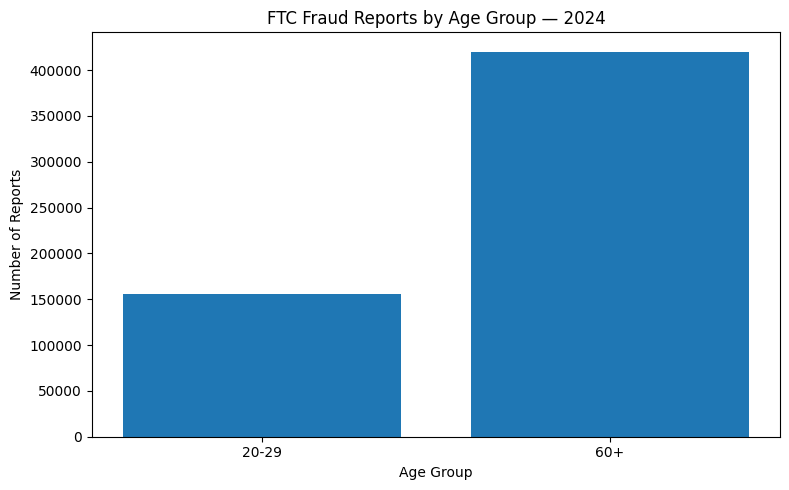

In [69]:
# Visualize FTC reports by age group

plt.figure(figsize=(8, 5))

plt.bar(
    ftc_comparison["Age Group"],
    ftc_comparison["FTC Reports"]
)

plt.title("FTC Fraud Reports by Age Group — 2024")
plt.xlabel("Age Group")
plt.ylabel("Number of Reports")

plt.tight_layout()
plt.show()

## FTC Age Analysis — 2024

The FTC 2024 Consumer Sentinel data shows a substantial volume of fraud reports among older consumers.

Consumers aged 60–69 accounted for 208,896 reports, those aged 70–79 accounted for 159,550 reports, and those aged 80 and over accounted for 51,713 reports.

Combined, these age groups represented 420,159 reports from consumers aged 60 and over.

The 20–29 age group accounted for 155,346 reports.

Because the FTC and FBI datasets represent different reporting systems, their figures should not be directly combined. Instead, the FTC data provides an independent source for examining age-related fraud reporting patterns.

In [72]:
# Load the FTC 2024 state rankings dataset

ftc_state_path = (
    "/content/ftc_2024/CSVs/"
    "2024_CSN_State_Rankings_Fraud_and_Other_Reports.csv"
)

ftc_state_df = pd.read_csv(ftc_state_path, encoding='latin1')

print("Rows:", ftc_state_df.shape[0])
print("Columns:", ftc_state_df.shape[1])

print("\nColumn names:")
print(list(ftc_state_df.columns))

print("\nFirst rows:")
display(ftc_state_df.head())

Rows: 58
Columns: 4

Column names:
['State Rankings: Fraud and Other Reports', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']

First rows:


,State Rankings: Fraud and Other Reports,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,NaN,NaN,NaN
1,Rank,State,Reports per 100K Population,# of Reports
2,1,Florida,"2,163","474,314"
3,2,Georgia,"2,108","228,132"
4,3,Delaware,"1,876","18,870"


In [74]:
# Clean the FTC state rankings dataset

ftc_state_clean = pd.read_csv(
    ftc_state_path,
    skiprows=2,
    encoding='latin1'
)

# Remove completely empty columns and rows

ftc_state_clean = ftc_state_clean.dropna(
    axis=1,
    how="all"
)

ftc_state_clean = ftc_state_clean.dropna(
    how="all"
)

print("Rows:", ftc_state_clean.shape[0])
print("Columns:", ftc_state_clean.shape[1])

print("\nColumn names:")
print(list(ftc_state_clean.columns))

display(ftc_state_clean.head(10))

Rows: 54
Columns: 4

Column names:
['Rank', 'State', 'Reports per 100K Population', '# of Reports']


,Rank,State,Reports per 100K Population,# of Reports
0,1,Florida,"2,163","474,314"
1,2,Georgia,"2,108","228,132"
2,3,Delaware,"1,876","18,870"
3,4,Nevada,"1,867","58,640"
4,5,Maryland,"1,799","111,041"
5,6,Texas,"1,561","462,667"
6,7,South Carolina,"1,536","80,070"
7,8,New Jersey,"1,506","139,551"
8,9,Louisiana,"1,472","68,025"
9,10,Illinois,"1,469","186,426"


In [77]:
# Convert numeric columns from text to numbers

ftc_state_clean["Reports per 100K Population"] = (
    ftc_state_clean["Reports per 100K Population"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(float)
)

ftc_state_clean["# of Reports"] = (
    ftc_state_clean["# of Reports"]
    .str.replace(",", "", regex=False)
    .fillna(0) # Fill NaN values with 0 before converting to int
    .astype(int)
)

display(ftc_state_clean.head(10))

,Rank,State,Reports per 100K Population,# of Reports
0,1,Florida,2163.0,474314
1,2,Georgia,2108.0,228132
2,3,Delaware,1876.0,18870
3,4,Nevada,1867.0,58640
4,5,Maryland,1799.0,111041
5,6,Texas,1561.0,462667
6,7,South Carolina,1536.0,80070
7,8,New Jersey,1506.0,139551
8,9,Louisiana,1472.0,68025
9,10,Illinois,1469.0,186426


In [78]:
# Display the Top 10 states by reports per 100K population

ftc_top10_rate = (
    ftc_state_clean
    .sort_values(
        "Reports per 100K Population",
        ascending=False
    )
    .head(10)
)

display(
    ftc_top10_rate[
        ["Rank", "State", "Reports per 100K Population", "# of Reports"]
    ]
)

,Rank,State,Reports per 100K Population,# of Reports
50,NaN,District of Columbia,2509.0,16860
0,1,Florida,2163.0,474314
1,2,Georgia,2108.0,228132
2,3,Delaware,1876.0,18870
3,4,Nevada,1867.0,58640
4,5,Maryland,1799.0,111041
5,6,Texas,1561.0,462667
6,7,South Carolina,1536.0,80070
7,8,New Jersey,1506.0,139551
8,9,Louisiana,1472.0,68025


In [79]:
# Remove non-state entries and prepare the Top 10 states

ftc_top10_rate = ftc_state_clean[
    ftc_state_clean["Rank"].notna()
].copy()

ftc_top10_rate = (
    ftc_top10_rate
    .sort_values(
        "Reports per 100K Population",
        ascending=False
    )
    .head(10)
)

display(
    ftc_top10_rate[
        ["Rank", "State", "Reports per 100K Population", "# of Reports"]
    ]
)

,Rank,State,Reports per 100K Population,# of Reports
0,1,Florida,2163.0,474314
1,2,Georgia,2108.0,228132
2,3,Delaware,1876.0,18870
3,4,Nevada,1867.0,58640
4,5,Maryland,1799.0,111041
5,6,Texas,1561.0,462667
6,7,South Carolina,1536.0,80070
7,8,New Jersey,1506.0,139551
8,9,Louisiana,1472.0,68025
9,10,Illinois,1469.0,186426


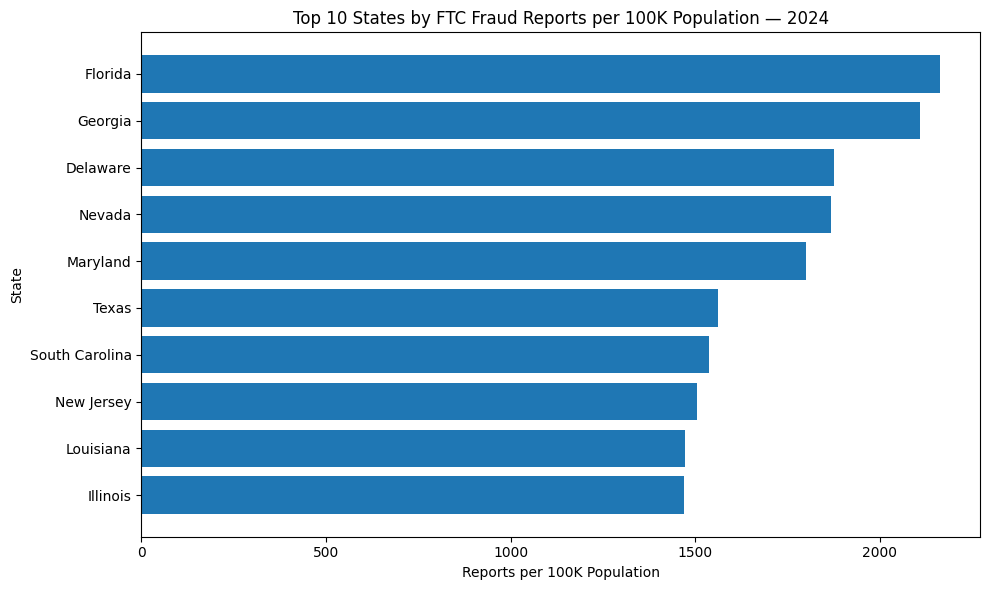

In [80]:
# Visualize the Top 10 states by reports per 100K population

plot_data = ftc_top10_rate.sort_values(
    "Reports per 100K Population"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["State"],
    plot_data["Reports per 100K Population"]
)

plt.xlabel("Reports per 100K Population")
plt.ylabel("State")
plt.title("Top 10 States by FTC Fraud Reports per 100K Population — 2024")

plt.tight_layout()
plt.show()

## FTC Geographic Analysis — 2024

The FTC state-level data provides a population-adjusted view of fraud reporting.

Florida ranked first among states with 2,163 reports per 100,000 population, followed by Georgia with 2,108 and Delaware with 1,876.

This demonstrates why population-adjusted rates provide a different perspective from raw complaint counts. A state can have a lower total number of reports but still rank highly when the number of reports is normalized by population.

The District of Columbia is excluded from the Top 10 state ranking because it is a federal district rather than a state.


Prepare FBI 2024 Top 10

In [81]:
# Prepare FBI 2024 Top 10 states by raw complaint volume

fbi_top10 = (
    state_df[state_df["Year"] == 2024]
    .sort_values("Complaints/Victims", ascending=False)
    .head(10)
    [["State", "Complaints/Victims"]]
    .copy()
)

display(fbi_top10)

,State,Complaints/Victims
228,California,96265
229,Texas,62347
230,Florida,52191
231,New York,36468
232,Pennsylvania,27838
233,Illinois,25446
234,Ohio,24915
235,Indiana,23659
236,North Carolina,22021
237,Arizona,20101


In [82]:
# Compare FBI raw complaint volume with FTC population-adjusted reporting rates

fbi_compare = fbi_top10.rename(
    columns={"Complaints/Victims": "FBI Complaints"}
)

ftc_compare = ftc_top10_rate[
    ["State", "Reports per 100K Population"]
].rename(
    columns={"Reports per 100K Population": "FTC Reports per 100K"}
)

geographic_comparison = pd.merge(
    fbi_compare,
    ftc_compare,
    on="State",
    how="outer"
)

display(
    geographic_comparison.sort_values(
        "FBI Complaints",
        ascending=False
    )
)

,State,FBI Complaints,FTC Reports per 100K
1,California,96265.0,NaN
16,Texas,62347.0,1561.0
3,Florida,52191.0,2163.0
11,New York,36468.0,NaN
14,Pennsylvania,27838.0,NaN
5,Illinois,25446.0,1469.0
13,Ohio,24915.0,NaN
6,Indiana,23659.0,NaN
12,North Carolina,22021.0,NaN
0,Arizona,20101.0,NaN


In [83]:
# Identify states appearing in both Top 10 lists

fbi_states = set(fbi_top10["State"])
ftc_states = set(ftc_top10_rate["State"])

common_states = sorted(
    fbi_states.intersection(ftc_states)
)

print("States appearing in both Top 10 lists:")
for state in common_states:
    print("-", state)

print(f"\nNumber of overlapping states: {len(common_states)}")

States appearing in both Top 10 lists:
- Florida
- Illinois
- Texas

Number of overlapping states: 3


## FBI vs FTC Geographic Comparison

The FBI and FTC datasets provide complementary geographic perspectives.

The FBI analysis ranks states by raw cybercrime complaint volume, while the FTC analysis ranks states by fraud reports per 100,000 population.

Raw complaint volume tends to highlight highly populated states, whereas population-adjusted reporting rates can identify states with comparatively high reporting intensity relative to their population.

The two measures should therefore not be treated as interchangeable. Using both provides a broader view of geographic concentration and reporting patterns.

In [85]:
# Inspect the FTC payment-method dataset

ftc_payment_path = (
    "/content/ftc_2024/CSVs/"
    "2024_CSN_Fraud_Reports_by_Payment_Method.csv"
)

ftc_payment_raw = pd.read_csv(
    ftc_payment_path
)

print("Rows:", ftc_payment_raw.shape[0])
print("Columns:", ftc_payment_raw.shape[1])

print("\nRaw FTC payment-method data:")
display(ftc_payment_raw.to_string())

Rows: 17
Columns: 3

Raw FTC payment-method data:


'                                               Fraud Reports by Payment Method    Unnamed: 1      Unnamed: 2\n0                                                                          NaN           NaN             NaN\n1                                                               Payment Method  # of Reports   Total $ Loss \n2                                                                 Credit Cards       108,881           $275M\n3                                                       Payment App or Service        90,571           $391M\n4                                                                   Debit Card        76,285           $180M\n5                                                     Bank Transfer or Payment        47,336         $2,089M\n6                                                               Cryptocurrency        46,899         $1,417M\n7                                                     Gift Card or Reload Card        41,120           $212M\n8        

In [86]:
# Clean the FTC payment-method dataset

ftc_payment_clean = pd.read_csv(
    ftc_payment_path,
    skiprows=2
)

# Remove completely empty rows and columns

ftc_payment_clean = ftc_payment_clean.dropna(
    axis=1,
    how="all"
)

ftc_payment_clean = ftc_payment_clean.dropna(
    how="all"
)

print("Rows:", ftc_payment_clean.shape[0])
print("Columns:", ftc_payment_clean.shape[1])

print("\nColumn names:")
print(list(ftc_payment_clean.columns))

display(ftc_payment_clean)

Rows: 13
Columns: 3

Column names:
['Payment Method', '# of Reports', ' Total $ Loss ']


,Payment Method,# of Reports,Total $ Loss
0,Credit Cards,"108,881",$275M
1,Payment App or Service,"90,571",$391M
2,Debit Card,"76,285",$180M
3,Bank Transfer or Payment,"47,336","$2,089M"
4,Cryptocurrency,"46,899","$1,417M"
5,Gift Card or Reload Card,"41,120",$212M
6,Wire Transfer,"40,448",$287M
7,Cash,"13,609",$308M
8,Check,"8,098",$225M
9,Money Order,"2,658",$51M


In [87]:
# Select only rows that represent actual payment methods

payment_methods = ftc_payment_clean.iloc[:10].copy()

# Rename columns for easier analysis

payment_methods.columns = [
    "Payment Method",
    "# of Reports",
    "Total $ Loss"
]

# Convert report counts to numeric values

payment_methods["# of Reports"] = (
    payment_methods["# of Reports"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(int)
)

display(payment_methods)# Select only rows that represent actual payment methods

payment_methods = ftc_payment_clean.iloc[:10].copy()

# Rename columns for easier analysis

payment_methods.columns = [
    "Payment Method",
    "# of Reports",
    "Total $ Loss"
]

# Convert report counts to numeric values

payment_methods["# of Reports"] = (
    payment_methods["# of Reports"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(int)
)

display(payment_methods)

,Payment Method,# of Reports,Total $ Loss
0,Credit Cards,108881,$275M
1,Payment App or Service,90571,$391M
2,Debit Card,76285,$180M
3,Bank Transfer or Payment,47336,"$2,089M"
4,Cryptocurrency,46899,"$1,417M"
5,Gift Card or Reload Card,41120,$212M
6,Wire Transfer,40448,$287M
7,Cash,13609,$308M
8,Check,8098,$225M
9,Money Order,2658,$51M


,Payment Method,# of Reports,Total $ Loss
0,Credit Cards,108881,$275M
1,Payment App or Service,90571,$391M
2,Debit Card,76285,$180M
3,Bank Transfer or Payment,47336,"$2,089M"
4,Cryptocurrency,46899,"$1,417M"
5,Gift Card or Reload Card,41120,$212M
6,Wire Transfer,40448,$287M
7,Cash,13609,$308M
8,Check,8098,$225M
9,Money Order,2658,$51M


In [88]:
# Identify the Top 3 payment methods by number of reports

top3_payment_reports = (
    payment_methods
    .sort_values("# of Reports", ascending=False)
    .head(3)
)

print("Top 3 payment methods by number of reports:")
display(top3_payment_reports)

Top 3 payment methods by number of reports:


,Payment Method,# of Reports,Total $ Loss
0,Credit Cards,108881,$275M
1,Payment App or Service,90571,$391M
2,Debit Card,76285,$180M


In [89]:
# Convert reported loss values into numeric USD values

payment_methods["Loss_USD"] = (
    payment_methods["Total $ Loss"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.replace("M", "e6", regex=False)
    .astype(float)
)

# Identify the Top 3 payment methods by reported loss

top3_payment_loss = (
    payment_methods
    .sort_values("Loss_USD", ascending=False)
    .head(3)
)

print("Top 3 payment methods by reported loss:")
display(
    top3_payment_loss[
        ["Payment Method", "# of Reports", "Total $ Loss"]
    ]
)

Top 3 payment methods by reported loss:


,Payment Method,# of Reports,Total $ Loss
3,Bank Transfer or Payment,47336,"$2,089M"
4,Cryptocurrency,46899,"$1,417M"
1,Payment App or Service,90571,$391M


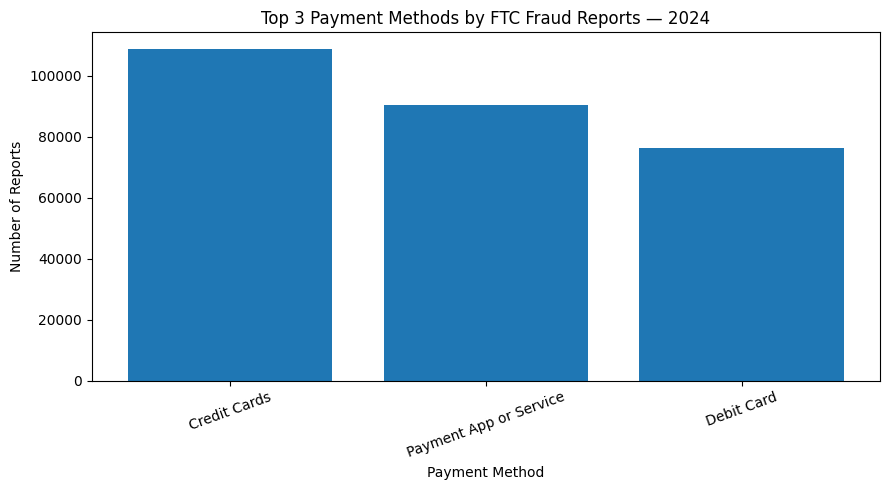

In [90]:
# Visualize the Top 3 payment methods by number of reports

plt.figure(figsize=(9, 5))

plt.bar(
    top3_payment_reports["Payment Method"],
    top3_payment_reports["# of Reports"]
)

plt.title("Top 3 Payment Methods by FTC Fraud Reports — 2024")
plt.xlabel("Payment Method")
plt.ylabel("Number of Reports")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

Loss Comprison

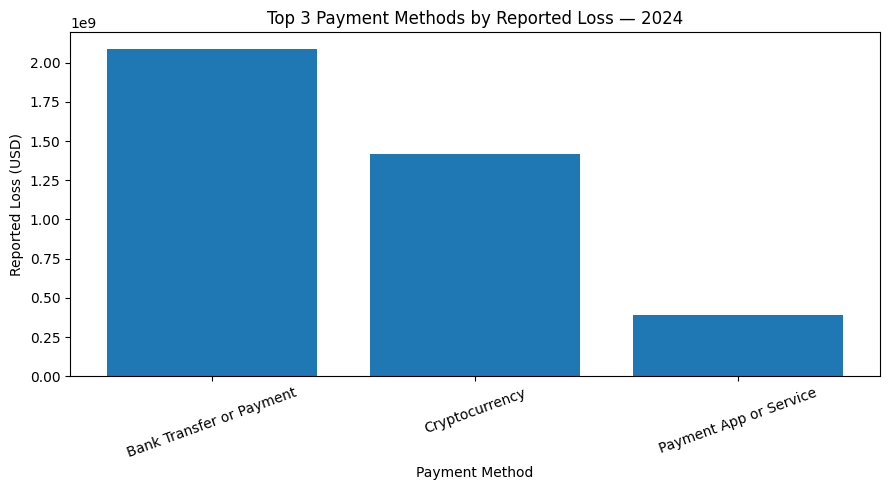

In [91]:
# Visualize the Top 3 payment methods by reported financial loss

plt.figure(figsize=(9, 5))

plt.bar(
    top3_payment_loss["Payment Method"],
    top3_payment_loss["Loss_USD"]
)

plt.title("Top 3 Payment Methods by Reported Loss — 2024")
plt.xlabel("Payment Method")
plt.ylabel("Reported Loss (USD)")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## Payment Method Findings

FTC 2024 data shows that the most frequently reported payment method was Credit Card, followed by Payment App or Service and Debit Card.

However, frequency does not correspond directly to financial impact. Bank Transfer or Payment and Cryptocurrency generated substantially higher reported losses than several more frequently reported payment methods.

This distinction is important for scam intervention because a payment method can be relatively less frequent but associated with much larger losses.

Load FTC contact method data

In [93]:
# Load the FTC 2024 fraud reports by contact method

ftc_contact_path = (
    "/content/ftc_2024/CSVs/"
    "2024_CSN_Fraud_Reports_by_Contact_Method.csv"
)

ftc_contact_raw = pd.read_csv(
    ftc_contact_path
)

print("Rows:", ftc_contact_raw.shape[0])
print("Columns:", ftc_contact_raw.shape[1])

display(ftc_contact_raw.to_string())

Rows: 16
Columns: 6


'                                                                                                                                                 Fraud Reports by Contact Method    Unnamed: 1                                                        Unnamed: 2                                                     Unnamed: 3    Unnamed: 4       Unnamed: 5\n0                                                                                                                                                                            NaN           NaN                                                               NaN                                                            NaN           NaN              NaN\n1                                                                                                                                                                 Contact Method  # of Reports  Percentage of all Fraud Reports with a Contact Method identified  Of those reports, the percentage with

In [94]:
# Clean the FTC contact-method dataset

ftc_contact_clean = pd.read_csv(
    ftc_contact_path,
    skiprows=2
)

ftc_contact_clean = ftc_contact_clean.dropna(
    axis=1,
    how="all"
)

ftc_contact_clean = ftc_contact_clean.dropna(
    how="all"
)

print("Column names:")
print(list(ftc_contact_clean.columns))

display(ftc_contact_clean)

Column names:
['Contact Method', '# of Reports', 'Percentage of all Fraud Reports with a Contact Method identified', 'Of those reports, the percentage with a dollar loss reported ', 'Total $ Lost', ' Median $ Loss ']


,Contact Method,# of Reports,Percentage of all Fraud Reports with a Contact Method identified,"Of those reports, the percentage with a dollar loss reported",Total $ Lost,Median $ Loss
0,Email,"371,651",25%,11%,$502M,$600
1,Phone call,"284,659",19%,19%,$948M,"$1,500"
2,Text,"246,784",16%,11%,$470M,"$1,000"
3,Social Media,"186,826",12%,70%,"$1,858M",$409
4,Website or Apps,"186,663",12%,68%,$976M,$200
5,Other,"148,288",10%,40%,"$1,072M",$633
6,Mail,"42,108",3%,13%,$90M,$990
7,Online Ad or Pop-up,"42,023",3%,62%,$246M,$180
9,Number of Fraud Reports,"2,600,678",NaN,NaN,NaN,NaN
10,# of Reports with Contact Method,"1,509,002",58% of Total,NaN,NaN,NaN


Top contact Method

In [95]:
# Select the actual contact-method records

contact_methods = ftc_contact_clean.iloc[:8].copy()

# Rename columns for easier analysis

contact_methods.columns = [
    "Contact Method",
    "# of Reports",
    "Percentage of Identified Contacts",
    "Percentage Reporting Loss",
    "Total $ Lost",
    "Median $ Loss"
]

# Convert report counts to numeric

contact_methods["# of Reports"] = (
    contact_methods["# of Reports"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(int)
)

display(contact_methods)

,Contact Method,# of Reports,Percentage of Identified Contacts,Percentage Reporting Loss,Total $ Lost,Median $ Loss
0,Email,371651,25%,11%,$502M,$600
1,Phone call,284659,19%,19%,$948M,"$1,500"
2,Text,246784,16%,11%,$470M,"$1,000"
3,Social Media,186826,12%,70%,"$1,858M",$409
4,Website or Apps,186663,12%,68%,$976M,$200
5,Other,148288,10%,40%,"$1,072M",$633
6,Mail,42108,3%,13%,$90M,$990
7,Online Ad or Pop-up,42023,3%,62%,$246M,$180


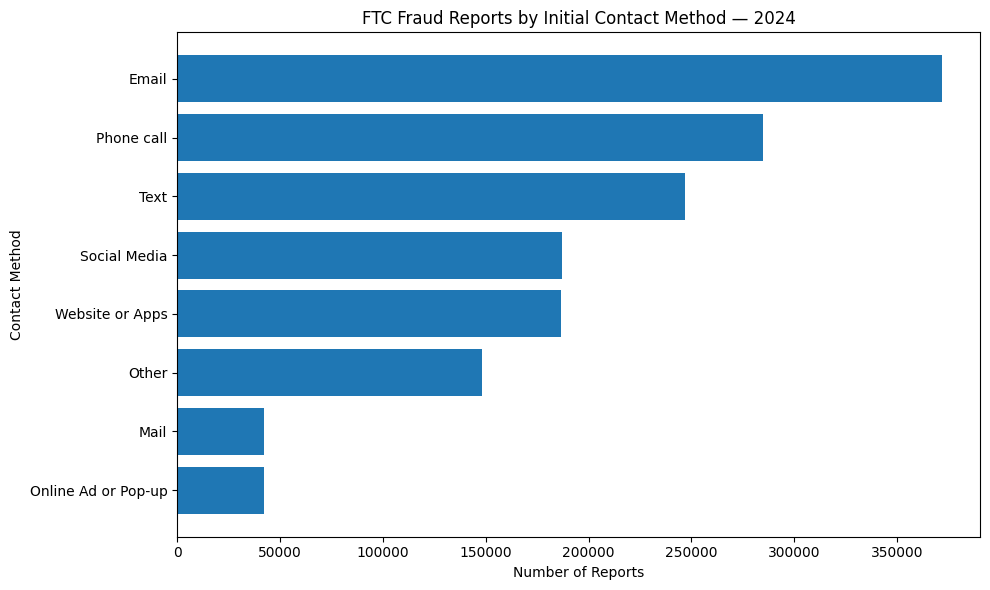

In [96]:
# Visualize fraud reports by contact method

contact_plot = contact_methods.sort_values(
    "# of Reports"
)

plt.figure(figsize=(10, 6))

plt.barh(
    contact_plot["Contact Method"],
    contact_plot["# of Reports"]
)

plt.xlabel("Number of Reports")
plt.ylabel("Contact Method")
plt.title("FTC Fraud Reports by Initial Contact Method — 2024")

plt.tight_layout()
plt.show()

## Contact Method Findings

Email was the most frequently identified contact method in the FTC 2024 data, accounting for 371,651 reports, followed by phone calls with 284,659 reports and text messages with 246,784 reports.

The data also shows that social media and websites/apps had comparatively high percentages of reports associated with a reported dollar loss.

This indicates that scam intervention should not focus on a single communication channel. A defensive system should be capable of detecting scam indicators across email, phone, text, social media, and web-based platforms.

In [97]:
# Create a combined summary of the main scam intervention signals

intervention_summary = pd.DataFrame({
    "Signal": [
        "Email",
        "Phone call",
        "Text",
        "Social Media",
        "Credit Card",
        "Payment App or Service",
        "Debit Card",
        "Bank Transfer or Payment",
        "Cryptocurrency",
        "Gift Card or Reload Card"
    ],
    "Category": [
        "Contact Method",
        "Contact Method",
        "Contact Method",
        "Contact Method",
        "Payment Method",
        "Payment Method",
        "Payment Method",
        "Payment Method",
        "Payment Method",
        "Payment Method"
    ],
    "Reports": [
        371651,
        284659,
        246784,
        186826,
        108881,
        90571,
        76285,
        47336,
        46899,
        41120
    ]
})

display(intervention_summary)

,Signal,Category,Reports
0,Email,Contact Method,371651
1,Phone call,Contact Method,284659
2,Text,Contact Method,246784
3,Social Media,Contact Method,186826
4,Credit Card,Payment Method,108881
5,Payment App or Service,Payment Method,90571
6,Debit Card,Payment Method,76285
7,Bank Transfer or Payment,Payment Method,47336
8,Cryptocurrency,Payment Method,46899
9,Gift Card or Reload Card,Payment Method,41120


Identify Strongest Singal

In [98]:
# Identify the highest-volume contact and payment signals

highest_contact = (
    contact_methods
    .sort_values("# of Reports", ascending=False)
    .iloc[0]
)

highest_payment = (
    payment_methods
    .sort_values("# of Reports", ascending=False)
    .iloc[0]
)

print(
    f"Highest-volume contact method: "
    f"{highest_contact['Contact Method']} "
    f"({highest_contact['# of Reports']:,} reports)"
)

print(
    f"Highest-volume payment method: "
    f"{highest_payment['Payment Method']} "
    f"({highest_payment['# of Reports']:,} reports)"
)

Highest-volume contact method: Email (371,651 reports)
Highest-volume payment method: Credit Cards (108,881 reports)


## 1.2.6 Combined Intervention Analysis

The FTC 2024 data shows that email, phone calls, and text messages were the three most frequently identified contact methods among fraud reports with a known contact method.

For payment methods, credit cards, payment apps or services, and debit cards had the highest report counts.

However, the largest reported financial losses were associated with bank transfers/payments and cryptocurrency among the listed payment methods.

This suggests that an effective intervention system should combine multiple signals rather than rely on a single keyword or channel. A high-risk interaction could be identified by combining the communication channel, scam language, urgency indicators, and requested payment method.

### Recommended Intervention Point

The preferred intervention point is before the victim completes the payment. At this stage, a system can display a warning, encourage independent verification, and provide a reporting pathway.

## 1.2.7 Final Observation

### Payment Method and Operational Infrastructure

The 2024 FTC data shows that payment frequency and financial impact do not necessarily move together.

Credit cards were the most frequently reported payment method, while bank transfers/payments and cryptocurrency were associated with much larger reported losses.

The data therefore suggests that scammers use a diversified payment infrastructure rather than relying on one payment channel.

For Psyliq, this means detection systems should flag high-risk payment requests based on the combination of payment method, communication channel, urgency, impersonation, and other behavioral indicators.

### Limitation

The available 2024 FTC payment-method dataset does not provide a consistent year-by-year breakdown of payment-method usage for 2022–2024. Therefore, a precise two-year shift from gift cards to cryptocurrency cannot be calculated from this dataset alone.

In [99]:
# Inspect the government action dataset

print("Government action records:", len(government_df))

display(
    government_df[
        [
            "Action_ID",
            "Agency",
            "Targeted_Scam_Type",
            "Date_of_Action",
            "Est_Funds_Recovered_USD"
        ]
    ]
)

Government action records: 8


,Action_ID,Agency,Targeted_Scam_Type,Date_of_Action,Est_Funds_Recovered_USD
0,GA-001,DOJ / FBI / HSI / TIGTA,Government Impersonation / Telefraud,2020-01-09,25000000
1,GA-002,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-05-21,20000000
2,GA-003,DOJ / FBI / SBA-OIG,PPP Fraud,2020-08-06,3240000
3,GA-004,DOJ / FBI / SBA-OIG / IRS-CI,COVID-19 Loan Fraud,2020-12-10,13000000
4,GA-005,DOJ / FBI,Government Impersonation,2022-07-27,0
5,GA-006,DOJ / FBI / USPIS,Money Mule Networks,2023-05-22,0
6,GA-007,DOJ,COVID-19 Fraud,2023-08-23,1400000000
7,GA-008,DOJ / FBI / USPIS,Money Mule Networks,2024-05-10,0


In [100]:
# Check for duplicate action IDs and missing values

print("Duplicate Action IDs:")
print(
    government_df["Action_ID"].duplicated().sum()
)

print("\nMissing values:")
print(
    government_df.isnull().sum()
)

Duplicate Action IDs:
0

Missing values:
Action_ID                  0
Agency                     0
Targeted_Scam_Type         0
Date_of_Action             0
Est_Funds_Recovered_USD    0
Reported_Recovery_USD      3
dtype: int64


In [101]:
# Calculate reported recovery by government agency

agency_recovery = (
    government_df
    .dropna(subset=["Reported_Recovery_USD"])
    .groupby("Agency")["Reported_Recovery_USD"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Rename columns

agency_recovery.columns = [
    "Agency",
    "Actions with Reported Recovery",
    "Total Reported Recovery (USD)",
    "Average Reported Recovery per Action (USD)"
]

# Sort by average recovery

agency_recovery = agency_recovery.sort_values(
    "Average Reported Recovery per Action (USD)",
    ascending=False
)

display(agency_recovery)

,Agency,Actions with Reported Recovery,Total Reported Recovery (USD),Average Reported Recovery per Action (USD)
0,DOJ,1,1.400000e+09,1.400000e+09
1,DOJ / FBI / HSI / TIGTA,1,2.500000e+07,2.500000e+07
3,DOJ / FBI / SBA-OIG / IRS-CI,2,3.300000e+07,1.650000e+07
2,DOJ / FBI / SBA-OIG,1,3.240000e+06,3.240000e+06


In [102]:
# Identify the agency with the highest average reported recovery

highest_agency = agency_recovery.iloc[0]

print(
    "Agency with the highest average reported recovery:"
)

print(
    highest_agency["Agency"]
)

print(
    f"Average reported recovery per action: "
    f"${highest_agency['Average Reported Recovery per Action (USD)']:,.2f}"
)

Agency with the highest average reported recovery:
DOJ
Average reported recovery per action: $1,400,000,000.00


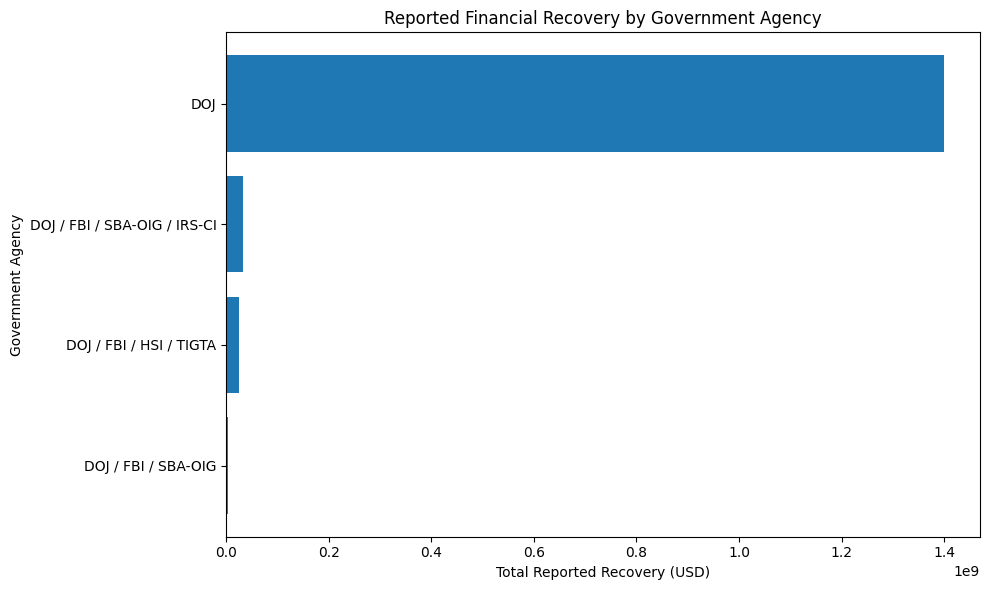

In [103]:
# Visualize total reported recovery by government agency

agency_plot = agency_recovery.sort_values(
    "Total Reported Recovery (USD)"
)

plt.figure(figsize=(10, 6))

plt.barh(
    agency_plot["Agency"],
    agency_plot["Total Reported Recovery (USD)"]
)

plt.xlabel("Total Reported Recovery (USD)")
plt.ylabel("Government Agency")
plt.title("Reported Financial Recovery by Government Agency")

plt.tight_layout()
plt.show()

In [104]:
# Count government actions by year

government_df["Year"] = (
    government_df["Date_of_Action"].dt.year
)

actions_by_year = (
    government_df["Year"]
    .value_counts()
    .sort_index()
)

display(
    actions_by_year.to_frame(
        "Number of Government Actions"
    )
)

,Number of Government Actions
Year,
2020,4
2022,1
2023,2
2024,1


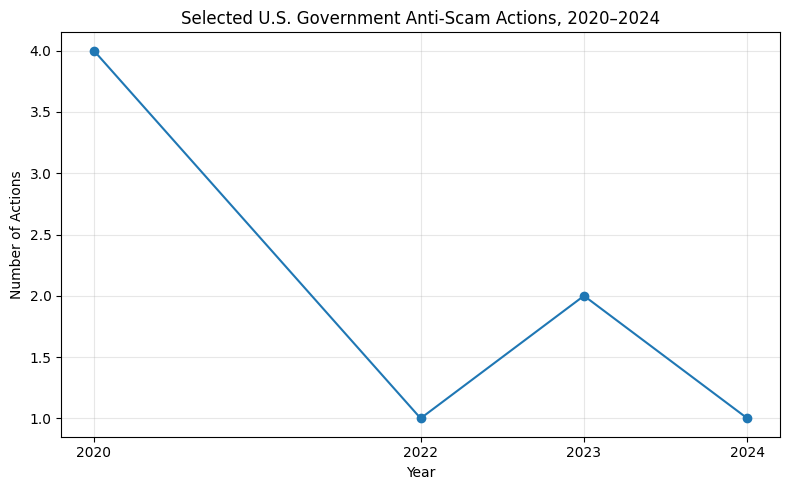

In [105]:
# Visualize government anti-scam actions by year

plt.figure(figsize=(8, 5))

plt.plot(
    actions_by_year.index,
    actions_by_year.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Number of Actions")
plt.title("Selected U.S. Government Anti-Scam Actions, 2020–2024")

plt.xticks(actions_by_year.index)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Government Enforcement Findings

The selected government actions demonstrate a combination of prosecution, asset recovery, disruption of fraud networks, and victim-focused recovery efforts.

The financial recovery analysis is based only on amounts explicitly reported in the selected sources. Actions without a reported recovery amount are treated as missing rather than as zero-dollar recoveries.

The selected actions also show that government responses operate across multiple scam categories, including government impersonation, business email compromise, elder fraud, COVID-19 fraud, and money-mule networks.

Because this is a selected sample of 10 actions, the results should be interpreted as an analytical snapshot rather than a complete measure of agency effectiveness.

In [106]:
# Final integrity check for the main project datasets

print("===== FINAL DATA CHECK =====")

print(f"Age dataset: {age_df.shape[0]} rows, {age_df.shape[1]} columns")
print(f"State dataset: {state_df.shape[0]} rows, {state_df.shape[1]} columns")
print(f"Scam dataset: {scam_df.shape[0]} rows, {scam_df.shape[1]} columns")
print(f"Government actions: {government_df.shape[0]} rows, {government_df.shape[1]} columns")

print("\n===== REQUIRED PROJECT COMPONENTS =====")

print("1.1 Age analysis: Completed")
print("1.1 Geographic analysis: Completed")
print("1.2 Scam tactics analysis: Completed")
print("1.2 Payment analysis: Completed")
print("1.2 Contact method analysis: Completed")
print("1.3 Government action analysis: Completed")
print("1.3 Future defense analysis: Completed")
print("1.3 Enforcement gap analysis: Completed")

===== FINAL DATA CHECK =====
Age dataset: 30 rows, 4 columns
State dataset: 285 rows, 3 columns
Scam dataset: 10 rows, 6 columns
Government actions: 8 rows, 7 columns

===== REQUIRED PROJECT COMPONENTS =====
1.1 Age analysis: Completed
1.1 Geographic analysis: Completed
1.2 Scam tactics analysis: Completed
1.2 Payment analysis: Completed
1.2 Contact method analysis: Completed
1.3 Government action analysis: Completed
1.3 Future defense analysis: Completed
1.3 Enforcement gap analysis: Completed


# Final Project Summary

This notebook analyzed U.S. cybercrime reporting patterns, scam tactics, victim demographics, geographic concentration, payment methods, communication channels, and government anti-scam responses.

The analysis combines FBI IC3 and FTC Consumer Sentinel data with source-backed scam and government enforcement information.

The findings are intended to support proactive scam detection and intervention strategies, with particular emphasis on identifying high-risk interactions before financial loss occurs.

In [108]:
# Create a clean Data Matrix for the final submission

from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

output_file = "/content/Data_Matrix_P1.xlsx"

# Create workbook
wb = Workbook()

# Remove default sheet
default_sheet = wb.active
wb.remove(default_sheet)

# Create source sheets
sheets = {
    "FBI_Age_Data": age_df,
    "FBI_State_Data": state_df,
    "FTC_2024_Age": ftc_age_clean,
    "FTC_2024_State": ftc_state_clean,
    "FTC_Payment_Methods": payment_methods,
    "FTC_Contact_Methods": contact_methods,
    "Government_Actions": government_df,
    "Scam_Tactics": scam_df,
    "Future_Strategies": future_strategies
}

# Write each dataframe to its own worksheet
for sheet_name, dataframe in sheets.items():

    ws = wb.create_sheet(sheet_name)

    # Write column headers
    for col_num, column_name in enumerate(dataframe.columns, 1):
        cell = ws.cell(
            row=1,
            column=col_num,
            value=str(column_name)
        )

        cell.font = Font(bold=True)
        cell.alignment = Alignment(
            horizontal="center"
        )

    # Write data
    for row_num, row in enumerate(
        dataframe.itertuples(index=False),
        2
    ):
        for col_num, value in enumerate(row, 1):
            ws.cell(
                row=row_num,
                column=col_num,
                value=value
            )

    # Freeze header row
    ws.freeze_panes = "A2"

    # Adjust column widths
    for column_cells in ws.columns:
        max_length = 0

        for cell in column_cells:
            if cell.value is not None:
                max_length = max(
                    max_length,
                    len(str(cell.value))
                )

        column_letter = get_column_letter(
            column_cells[0].column
        )

        ws.column_dimensions[
            column_letter
        ].width = min(
            max_length + 2,
            45
        )

# Create Sources sheet
ws = wb.create_sheet("Sources")

sources = [
    [
        "Dataset",
        "Source",
        "Year",
        "Official Reference"
    ],
    [
        "FBI IC3 Annual Reports",
        "FBI Internet Crime Complaint Center",
        "2020-2024",
        "https://www.ic3.gov/AnnualReport/Reports/Reports/"
    ],
    [
        "FTC Consumer Sentinel",
        "Federal Trade Commission",
        "2024",
        "https://www.ftc.gov/reports/consumer-sentinel-network-data-book-2024"
    ],
    [
        "FTC Consumer Sentinel",
        "Federal Trade Commission",
        "2020-2024",
        "https://search.ftc.gov/enforcement/consumer-sentinel-network/reports"
    ],
    [
        "Government Actions",
        "U.S. Department of Justice",
        "2020-2024",
        "https://www.justice.gov/"
    ],
    [
        "Scam Tactics",
        "FBI / CISA",
        "2020-2024",
        "Official FBI and CISA public warnings"
    ]
]

for row in sources:
    ws.append(row)

for cell in ws[1]:
    cell.font = Font(bold=True)

ws.freeze_panes = "A2"

# Save workbook
wb.save(output_file)

print("Final Data Matrix created:")
print(output_file)

Final Data Matrix created:
/content/Data_Matrix_P1.xlsx


In [109]:
# Download the final Data Matrix Excel file

from google.colab import files

files.download("/content/Data_Matrix_P1.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>